# Assignment 2 — Handcrafted Features

Bag of Visual Words (BoVW), VLAD and Fisher Vector for object classification and retrieval.
Stages follow the assignment handout.

| Part | Stage | Description |
|------|-------|-------------|
| 1 | A | Prepare the data and build BoVW (data stats, inspection, global vs 2×2 tiling, K = 256/512/1024) |
| 1 | B | Train a motorbike classifier (C on validation, ranked training images, relevant visual words) |
| 1 | C | Test and evaluate retrieval (motorbike: PR curve, AP, P@K/R@K) |
| 1 | D | Other categories (per-class AP, mAP, confusion matrices) |
| 1 | E | Normalization and spatial information |
| 1 | F | Hellinger feature map |
| 1 | G | Vary the number of training images |
| 2 | H | VLAD |
| 2 | I | Fisher Vector (+ BoVW vs VLAD vs FV comparison) |
| 3 | A | Experimental design: large vocabulary + PCA vs small vocabulary |
| — | — | Discussion (answers to the handout questions) |

**Protocol.** Fixed train/val/test splits (`data/splits`), identical for all methods. Every hyperparameter
(K, C, normalization, spatial tiling) is selected on **validation** only. The test set is used for the reported
numbers; the C/D test results use the baseline L2 setting and the final selected setting is re-evaluated once after Stage F.

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
import sys, os, time, platform, warnings
from functools import lru_cache
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, sklearn
from IPython.display import display
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', None)

# cv2.imread silently returns None on Windows for paths with non-ASCII characters.
# Patch it to fall back to np.fromfile + imdecode, which handles Unicode paths.
_cv2_imread_orig = cv2.imread
def _imread_unicode(path, flags=cv2.IMREAD_COLOR):
    im = _cv2_imread_orig(path, flags)
    if im is None:
        buf = np.fromfile(str(path), dtype=np.uint8)
        if len(buf) > 0:
            im = cv2.imdecode(buf, flags)
    return im
cv2.imread = _imread_unicode

from src import utils, encoders
from src.visualization import (displayRankedImageList,
                                displayPrecisionRecallCurve,
                                RelevantVisualWordsDisplay)

# Paths — notebook lives in code/, data in ../data/
NOTEBOOK_DIR = Path('.').resolve()
DATA_DIR  = (NOTEBOOK_DIR / '..' / 'data').resolve()
IMG_DIR   = DATA_DIR / 'images'
ENC_DIR   = DATA_DIR / 'encoders'
ENCD_DIR  = DATA_DIR / 'encodings'
SPLITS_FILE = DATA_DIR / 'splits' / 'splits.json'

CATEGORIES = ['aeroplane', 'car', 'horse', 'motorbike', 'person']
C_VALUES   = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
SEED       = 42

np.random.seed(SEED)
assert DATA_DIR.exists(), f'Data directory not found: {DATA_DIR}'
print(f'Data dir : {DATA_DIR}')
print(f'Python {platform.python_version()} | numpy {np.__version__} | scikit-learn {sklearn.__version__} '
      f'| OpenCV {cv2.__version__} | pandas {pd.__version__}')
print(f'Machine  : {platform.processor() or platform.machine()}, {os.cpu_count()} logical CPUs, no GPU used')

Data dir : C:\Users\carol\OneDrive\Ambiente de Trabalho\UNI\Mestrado\2º Ano\1º Semestre\Inteligência Articial para Visão por Computador (IAVC)\Assignments\IAVC_Projects\Assignment2\data
Python 3.11.17 | numpy 2.4.6 | scikit-learn 1.9.1 | OpenCV 4.13.0 | pandas 3.0.5
Machine  : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel, 16 logical CPUs, no GPU used


### Hardware and reproducibility note

- **Hardware**: CPU only (see the machine line printed above). All timings are wall-clock on CPU.
- **Timings**: SVM training time and inference time (scoring incl. normalization / PCA) are measured here.
  Per-image *encoding* time (dense SIFT + PCA + encoding, model already loaded) is measured in Stage I.
  Codebook / GMM fitting was done offline when the encoders in `data/encoders` were built and is **not** re-timed.
- **Software**: see the version line above; pinned in `env-win.yml`.
- **Seeds**: `SEED = 42` for SVMs and PCA; Stage G repeats random subsampling with seeds {0, 42, 123}.
  The vocabularies (k-means / GMM) are the fixed precomputed ones, so their randomness is **not** averaged out.

In [2]:
# ── Helper functions ──────────────────────────────────────────────────────────
# Metrics
def compute_ap(labels, scores):
    return float(average_precision_score(labels, scores))

def compute_pk(labels, scores, k):
    order = np.argsort(scores)[::-1]
    return float(np.mean(labels[order[:k]] > 0))

def compute_rk(labels, scores, k):
    order = np.argsort(scores)[::-1]
    n_pos = int(np.sum(labels > 0))
    return 0.0 if n_pos == 0 else float(np.sum(labels[order[:k]] > 0) / n_pos)

# Feature transforms (rows = images)
def identity(x): return x

def l2norm(x):
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-10)

def l1norm(x):
    return x / (np.sum(np.abs(x), axis=1, keepdims=True) + 1e-10)

def sqrt_only(x):          # Hellinger feature map without any normalization
    return np.sqrt(x)

def hellinger(x):          # L1 -> sqrt -> L2 (BoVW histograms are non-negative)
    return l2norm(np.sqrt(l1norm(x)))

# Data access (cached: every call returns the same read-only arrays)
@lru_cache(maxsize=None)
def load_enc(category, encoding, subset='train'):
    """Positives of `category` + background negatives. Returns (X, y in {+1,-1}, names)."""
    return utils.loadEncodingSubset(category, encoding, subset, root_dir=str(DATA_DIR))

def get_xy(category, encoding, subset, spatial=True):
    x, y, n = load_enc(category, encoding, subset)
    return (x if spatial else encoders.removeSpatialInformation(x)), y, n

# SVM helpers
def sweep_c(x_tr, y_tr, x_val, y_val, transform=l2norm):
    """Validation AP for every C in C_VALUES."""
    x_tr_n, x_val_n = transform(x_tr), transform(x_val)
    res = {}
    for C in C_VALUES:
        W, b = utils.train_svm(x_tr_n, y_tr, C=C, seed=SEED)
        res[C] = compute_ap(y_val, W @ x_val_n.T + b)
    return res

def best_c(res):
    return max(res, key=res.get)

def train_eval(x_tr, y_tr, x_ev, y_ev, C, transform=l2norm):
    t0 = time.time(); W, b = utils.train_svm(transform(x_tr), y_tr, C=C, seed=SEED); t_train = time.time() - t0
    t0 = time.time(); scores = W @ transform(x_ev).T + b; t_infer = time.time() - t0   # incl. normalization / PCA
    return W, b, scores, compute_ap(y_ev, scores), t_train, t_infer

def eval_all_cats(encoding, transform=l2norm, spatial=True, subset='test', C=None):
    """One-vs-rest SVM per category, trained on train. C chosen per category on val unless given.
    Returns (dict of AP per category + mAP, dict of per-category results)."""
    aps, svms = {}, {}
    for cat in CATEGORIES:
        x_tr, y_tr, _ = get_xy(cat, encoding, 'train', spatial)
        x_va, y_va, _ = get_xy(cat, encoding, 'val', spatial)
        c = C if C is not None else best_c(sweep_c(x_tr, y_tr, x_va, y_va, transform))
        x_ev, y_ev, n_ev = get_xy(cat, encoding, subset, spatial)
        W, b, scores, ap, t_tr, t_inf = train_eval(x_tr, y_tr, x_ev, y_ev, c, transform)
        aps[cat] = ap
        svms[cat] = {'W': W, 'b': b, 'y': y_ev, 'scores': scores, 'names': n_ev,
                     'C': c, 't_train': t_tr, 't_infer': t_inf}
    aps['mAP'] = float(np.mean([aps[c] for c in CATEGORIES]))
    return aps, svms

def thr_metrics(y, scores, thr=0.0):
    """Confusion matrix + precision/recall/F1/accuracy at a fixed decision threshold."""
    pred = np.where(scores >= thr, 1, -1)
    (tp, fn), (fp, tn) = confusion_matrix(y, pred, labels=[1, -1])
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec  = tp / (tp + fn) if tp + fn else 0.0
    return dict(TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn), Precision=prec, Recall=rec,
                F1=f1_score(y, pred, pos_label=1, zero_division=0), Accuracy=float(np.mean(pred == y)))

def ensure_encoding(k):
    """Return the name of the 2x2-tiled BoVW encoding with K words, building it if it is missing."""
    enc_name = f'bovw_K{k}_C0'
    encd_dir = ENCD_DIR / enc_name
    needed = [encd_dir / f'{c}_{s}.npz' for c in CATEGORIES + ['background'] for s in ('train', 'val', 'test')]
    if all(f.exists() for f in needed):
        return enc_name
    from src.train import sampleLocalFeatures, train_encoder
    from src.utils import loadSplitsTable, loadSplitsDataTables
    from src.extract import encodeFeatures
    enc_file = ENC_DIR / f'{enc_name}.npz'
    if not enc_file.exists():
        print(f'  Training encoder {enc_name} ...'); t0 = time.time()
        df_tr = loadSplitsTable(str(SPLITS_FILE), str(IMG_DIR), subset='train', per_class=150, random_state=SEED)
        descs = sampleLocalFeatures(df_tr, num_samples=400, seed=SEED)
        enc_dict = train_encoder(descs, encoder_type='bovw', num_words=k, pca_dim=0, seed=SEED)
        ENC_DIR.mkdir(parents=True, exist_ok=True)
        np.savez(str(enc_file), **enc_dict)
        print(f'  done in {time.time()-t0:.0f}s')
    print(f'  Extracting encodings {enc_name} ...'); t0 = time.time()
    df_all = loadSplitsDataTables(str(SPLITS_FILE), str(IMG_DIR))
    encd_dir.mkdir(parents=True, exist_ok=True)
    encodeFeatures(df_all, str(enc_file), output_dir=str(encd_dir), cache_dir='', overwrite=False, jobs=1)
    print(f'  done in {time.time()-t0:.0f}s')
    return enc_name

def pr_grid(svms, aps, title, color='steelblue'):
    fig, axes = plt.subplots(2, 3, figsize=(13, 8)); axes = axes.flatten()
    for ax, cat in zip(axes, CATEGORIES):
        prec, rec, _ = precision_recall_curve(svms[cat]['y'], svms[cat]['scores'])
        ax.plot(rec, prec, lw=1.5, color=color); ax.fill_between(rec, prec, alpha=0.15, color=color)
        ax.set_title(f'{cat}   AP = {aps[cat]:.4f}'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
        ax.set_ylim(0, 1.02); ax.set_xlim(0, 1.02); ax.grid(alpha=0.3)
    axes[-1].axis('off')
    fig.suptitle(f'{title}   mAP = {aps["mAP"]:.4f}', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()

def ap_table(results):
    """results: {label: aps dict} -> DataFrame of AP per category + mAP."""
    return pd.DataFrame({k: {c: f'{v[c]:.4f}' for c in CATEGORIES + ['mAP']} for k, v in results.items()}).T

print('Helper functions loaded.')

Helper functions loaded.


---
# Part 1 — Handcrafted features: BoVW and linear SVM

BoVW on dense SIFT (PHOW) descriptors. Precomputed encoder provided with the assignment: `bovw_K512_C0`
(K = 512, no PCA, 2×2 spatial tiling → 4 × 512 = **2048** dimensions).

## Stage A — Prepare the data and build BoVW

Dense SIFT descriptors are precomputed. A vocabulary of $K$ visual words is learnt with k-means on **training** descriptors only,
each image is encoded as a BoVW histogram (optionally one histogram per $2\times2$ tile, concatenated).
This stage: (1) dataset statistics, (2) visual inspection, (3) global histogram vs spatial tiling, (4) vocabulary sizes $K\in\{256,512,1024\}$.
Selection is done on validation, for the motorbike classifier with L2 normalization (C swept; the norm is revisited in Stages E/F).

**Questions (answered in the Discussion):** how to choose K; how does tiling help / when does it hurt; how does K affect capacity, quantization error, computation and storage.

In [3]:
# ── Stage A — Dataset statistics (positives per category + shared background) ──
ENC_PROVIDED = 'bovw_K512_C0'
rows = []
for cat in CATEGORIES:
    row = {'category': cat}
    for split in ('train', 'val', 'test'):
        _, y, _ = load_enc(cat, ENC_PROVIDED, split)
        row[f'{split} pos'] = int((y > 0).sum()); row[f'{split} bg'] = int((y < 0).sum())
    rows.append(row)
display(pd.DataFrame(rows).set_index('category'))

x_dim = load_enc('motorbike', ENC_PROVIDED, 'train')[0].shape[1]
print(f'Provided encoding {ENC_PROVIDED}: {x_dim}-dim (= 512 words x 4 tiles)')

,train pos,train bg,val pos,val bg,test pos,test bg
category,,,,,,
aeroplane,90,815,22,204,126,1077
car,301,815,75,204,337,1077
horse,111,815,28,204,148,1077
motorbike,96,815,24,204,125,1077
person,820,815,205,204,983,1077


Provided encoding bovw_K512_C0: 2048-dim (= 512 words x 4 tiles)


#### Stage A: visual inspection

Representative positive images per category and background (negative) examples; note variation in scale, viewpoint, illumination and clutter.

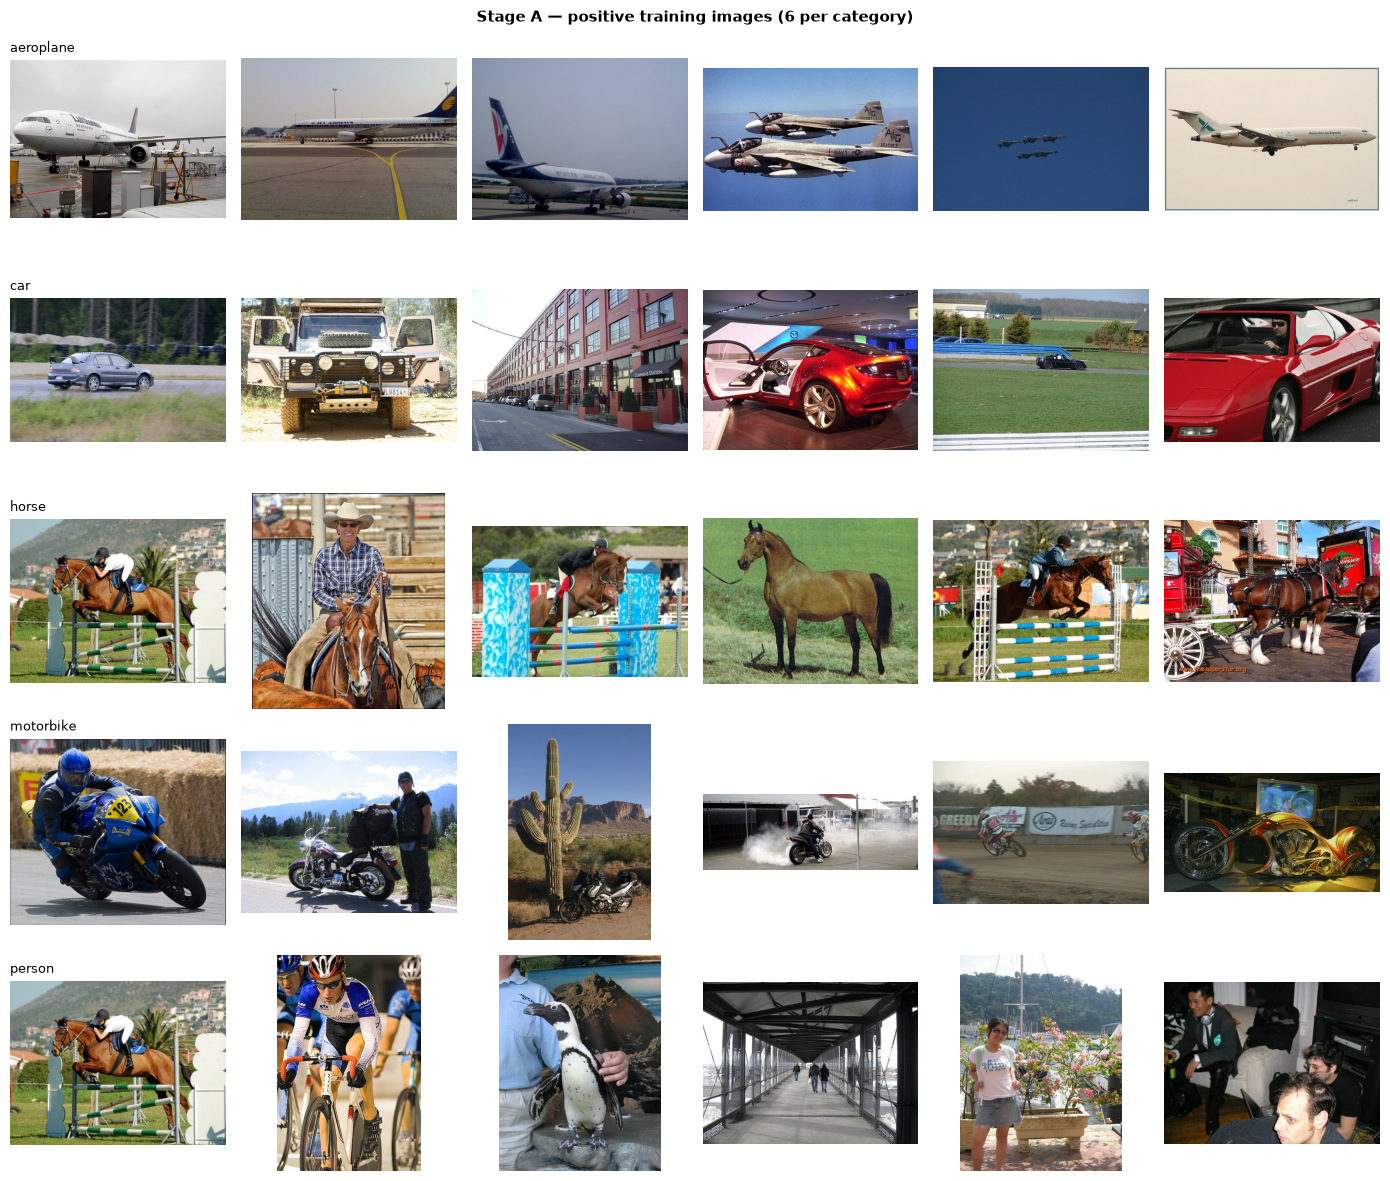

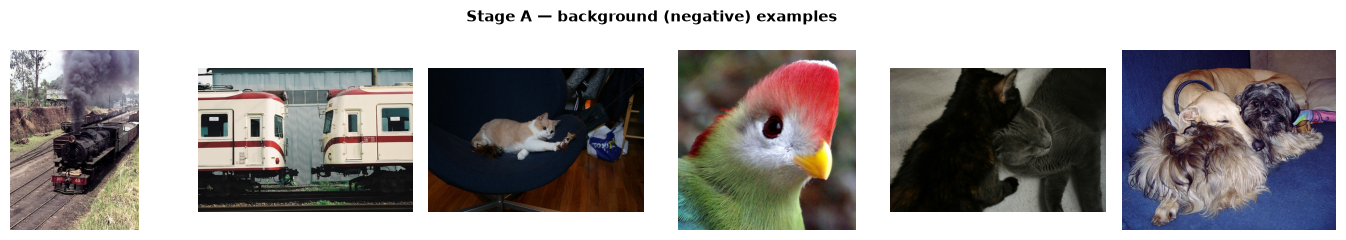

In [4]:
# ── Stage A — visual inspection ──────────────────────────────────────────────
n_show = 6
fig, axes = plt.subplots(len(CATEGORIES), n_show, figsize=(14, len(CATEGORIES) * 2.4))
for r, cat in enumerate(CATEGORIES):
    _, y_c, names_c = load_enc(cat, ENC_PROVIDED, 'train')
    pos_names = [n for n, y in zip(names_c, y_c) if y > 0][:n_show]
    for c in range(n_show):
        axes[r][c].axis('off')
        if c < len(pos_names):
            img = cv2.imread(str(IMG_DIR / f'{pos_names[c]}.jpg'))
            if img is not None:
                axes[r][c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[r][0].set_title(cat, fontsize=9, loc='left')
fig.suptitle('Stage A — positive training images (6 per category)', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

_, y_m, names_m = load_enc('motorbike', ENC_PROVIDED, 'train')
neg_names = [n for n, y in zip(names_m, y_m) if y < 0][:n_show]
fig, axes = plt.subplots(1, n_show, figsize=(14, 2.4))
for ax, name in zip(axes, neg_names):
    img = cv2.imread(str(IMG_DIR / f'{name}.jpg'))
    if img is not None:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis('off')
fig.suptitle('Stage A — background (negative) examples', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

**Observations on the inspected images** (first 6 training positives per category in file order, not hand-picked for diversity; 6 background images).
- *Scale* varies a lot inside a category: close-ups where the object fills the frame (aeroplane, car, motorbike) next to tiny instances (jets that are dots in the sky, a car on a far road, a motorbike beside a large cactus).
- *Viewpoint / pose*: side, front and rear views of cars and aeroplanes; riders leaning in bends; horses jumping vs standing.
- *Illumination / colour*: bright outdoor scenes vs dark indoor ones (show bikes, dark rooms), very different colours inside one class.
- *Clutter and context*: motorbikes on race tracks with hay bales and crowds, cars on streets, horses together with riders and fences.
- *Classes overlap*: the same image can be positive for several categories (the first *person* image appears to be the show-jumping *horse* image), so person positives often contain horses, bicycles, etc.
- *Background* is not "empty": steam trains, trams, cats, dogs and birds — animals and vehicles that act as hard negatives for the horse/car/motorbike classifiers.

#### Stage A: global histogram vs $2\times2$ tiling, and vocabulary size $K$

For each $K\in\{256,512,1024\}$: L2-normalized histograms, linear SVM with $C$ swept on validation, motorbike validation AP,
for the single **global** histogram ($K$-dim, tiles averaged) and the **2×2 tiling** ($4K$-dim).

dim  AP val    C*
K    spatial                       
256  global       256  0.3939  10.0
     tiling 2x2  1024  0.5901   1.0
512  global       512  0.4549  10.0
     tiling 2x2  2048  0.5549  10.0
1024 global      1024  0.4911  10.0
     tiling 2x2  4096  0.5100  10.0


Selected on validation: K = 256  (bovw_K256_C0, 1024-dim with tiling)
  K= 256: tiling gain over global = +19.6 p.p.
  K= 512: tiling gain over global = +10.0 p.p.
  K=1024: tiling gain over global = +1.9 p.p.


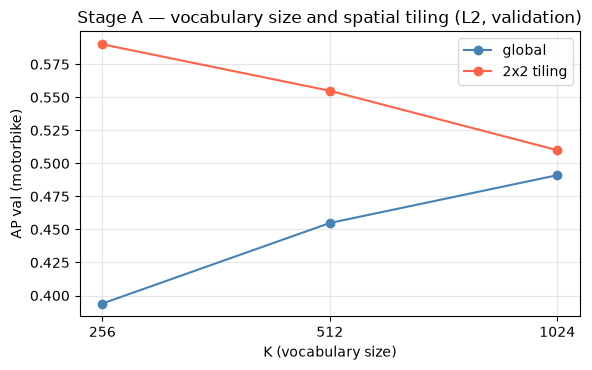

In [5]:
# ── Stage A — global vs 2x2 tiling x vocabulary size K (validation, motorbike, L2) ──
K_VALUES = [256, 512, 1024]
k_res = {}
for k in K_VALUES:
    enc = ensure_encoding(k)
    for spatial in (False, True):
        x_tr, y_tr, _ = get_xy('motorbike', enc, 'train', spatial)
        x_va, y_va, _ = get_xy('motorbike', enc, 'val', spatial)
        res = sweep_c(x_tr, y_tr, x_va, y_va, l2norm)
        c = best_c(res)
        k_res[(k, spatial)] = {'enc': enc, 'dim': x_tr.shape[1], 'ap': res[c], 'C': c}

df_k = pd.DataFrame([{'K': k, 'spatial': 'tiling 2x2' if s else 'global', 'dim': v['dim'],
                      'AP val': round(v['ap'], 4), 'C*': v['C']} for (k, s), v in k_res.items()])
display(df_k.set_index(['K', 'spatial']))

# Selection (validation): best K for the tiled representation
K_BEST = max(K_VALUES, key=lambda k: k_res[(k, True)]['ap'])
ENC    = k_res[(K_BEST, True)]['enc']
print(f'\nSelected on validation: K = {K_BEST}  ({ENC}, {k_res[(K_BEST, True)]["dim"]}-dim with tiling)')
for k in K_VALUES:
    print(f'  K={k:4d}: tiling gain over global = {(k_res[(k, True)]["ap"] - k_res[(k, False)]["ap"]) * 100:+.1f} p.p.')

fig, ax = plt.subplots(figsize=(6, 3.8))
for spatial, lab, col in [(False, 'global', 'steelblue'), (True, '2x2 tiling', 'tomato')]:
    ax.plot(K_VALUES, [k_res[(k, spatial)]['ap'] for k in K_VALUES], 'o-', color=col, label=lab)
ax.set_xscale('log', base=2); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
ax.set_xlabel('K (vocabulary size)'); ax.set_ylabel('AP val (motorbike)')
ax.set_title('Stage A — vocabulary size and spatial tiling (L2, validation)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Stage B — Train a motorbike classifier

Motorbike images are positives, background images are negatives. Linear SVM on the L2-normalized BoVW histograms of the selected $K$
(2×2 tiling); $C\in\{0.001,\dots,100\}$ chosen on validation. Training images are then ranked by decision score and the visual words
with large classifier weights are displayed (*RelevantVisualWordsDisplay*).

**Questions:** what do we expect; do the top-ranked images share object features or context; why can training performance be high but fail on new images?

C sweep (motorbike, bovw_K256_C0, L2, 2x2 tiling): AP val
  C =    0.001  0.1813
  C =    0.010  0.1722
  C =    0.100  0.5173
  C =    1.000  0.5901   <- best
  C =   10.000  0.5205
  C =  100.000  0.4640


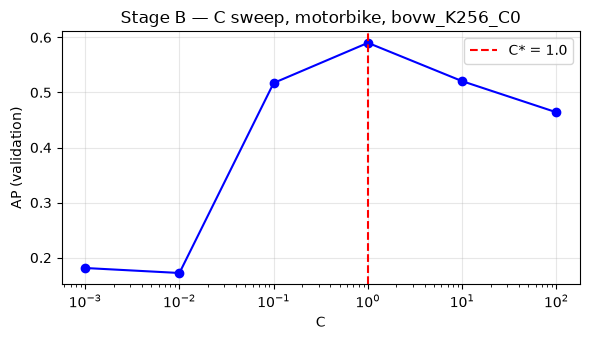


AP on TRAINING data = 0.8702   vs   AP on validation = 0.5901

Ranked TRAINING images (motorbike):


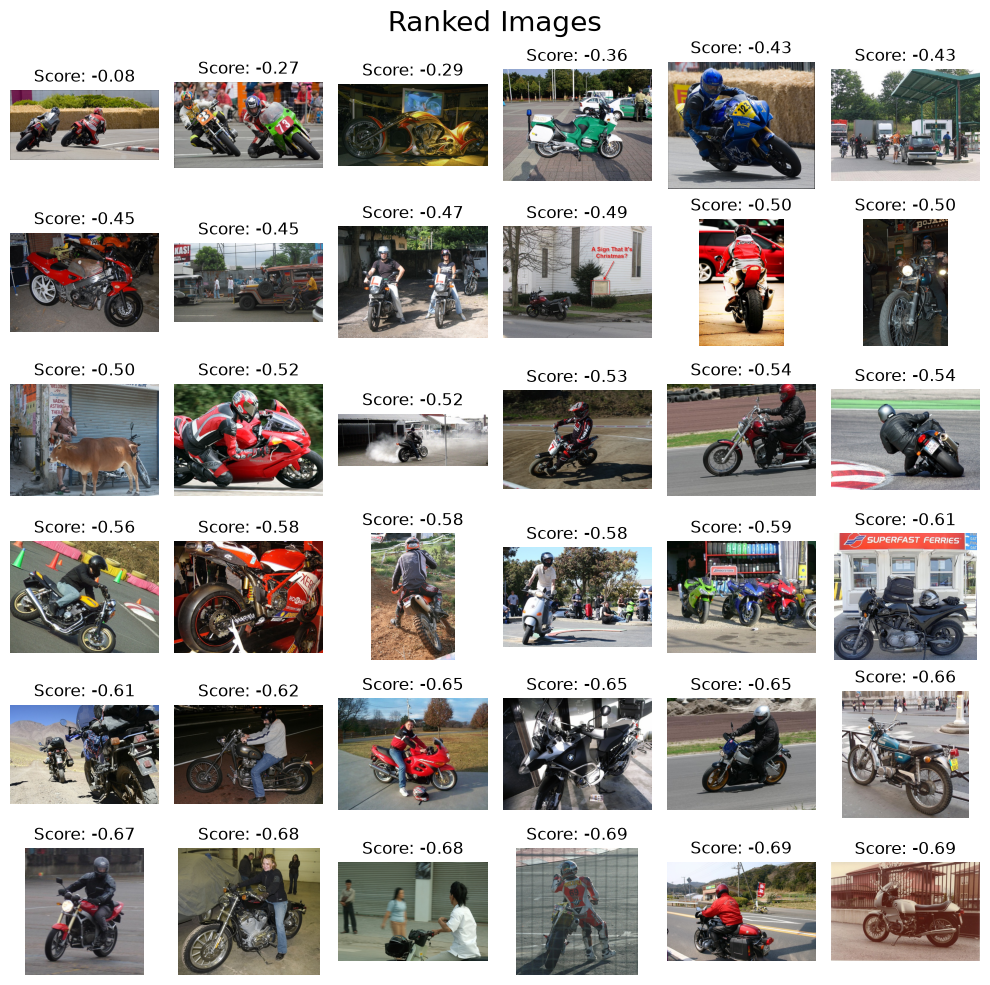

In [6]:
# ── Stage B — C sweep on validation, train, rank training images ─────────────
x_tr, y_tr, names_tr = get_xy('motorbike', ENC, 'train')
x_va, y_va, names_va = get_xy('motorbike', ENC, 'val')

c_res = sweep_c(x_tr, y_tr, x_va, y_va, l2norm)
C_B = best_c(c_res)
print(f'C sweep (motorbike, {ENC}, L2, 2x2 tiling): AP val')
for C in C_VALUES:
    print(f'  C = {C:8.3f}  {c_res[C]:.4f}' + ('   <- best' if C == C_B else ''))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(C_VALUES, [c_res[c] for c in C_VALUES], 'bo-', ms=6)
ax.axvline(C_B, color='r', ls='--', label=f'C* = {C_B}')
ax.set_xlabel('C'); ax.set_ylabel('AP (validation)'); ax.set_title(f'Stage B — C sweep, motorbike, {ENC}')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

W_b, b_b = utils.train_svm(l2norm(x_tr), y_tr, C=C_B, seed=SEED)
train_scores = W_b @ l2norm(x_tr).T + b_b
print(f'\nAP on TRAINING data = {compute_ap(y_tr, train_scores):.4f}   vs   AP on validation = {c_res[C_B]:.4f}')

print('\nRanked TRAINING images (motorbike):')
train_paths = [str(IMG_DIR / f'{n}.jpg') for n in names_tr]
displayRankedImageList(train_scores, train_paths, uniform=False, figzize=(10, 10))

In [7]:
# ── Stage B — relevant visual words (highest-ranked training image) ──────────
# RelevantVisualWordsDisplay folds the 2x2 tile weights per word and applies sqrt+L2 to the image histogram internally.
import ipywidgets as widgets
encoder_obj = encoders.ImageEncoder(str(ENC_DIR / f'{ENC}.npz'))
top = int(np.argmax(train_scores))
print(f'Selected image: {names_tr[top]}  (score = {train_scores[top]:.4f})')
img = encoders.standarizeImage(str(IMG_DIR / f'{names_tr[top]}.jpg'))
rvw = RelevantVisualWordsDisplay(img, W_b, encoder_obj)

@widgets.interact(rank=(0, min(len(rvw) - 1, 19)))
def display_rvw(rank=0):
    rvw.plot(rank, figsize=(12, 8))

Selected image: 005260  (score = -0.0789)
Number of keypoints: 25111 Descriptor dimension: 128


interactive(children=(IntSlider(value=0, description='rank', max=19), Output()), _dom_classes=('widget-interac…

## Stage C — Test and evaluate retrieval (motorbike)

Apply the classifier trained in Stage B (**baseline: L2 normalization, tiling, selected K, C\* from validation**) to the held-out test set,
rank by the continuous SVM decision score, plot the precision–recall curve and compute AP.
Positive class = motorbike; AP = area under the PR curve (`sklearn.average_precision_score`, step-wise, no interpolation).

**Questions:** why is the bias term irrelevant for the ordering of one fixed linear classifier; how does the position of positives in the ranking shape the PR curve and AP.

Correctly retrieved in the top 36: 25 / 36   (125 positives in 1202 test images)


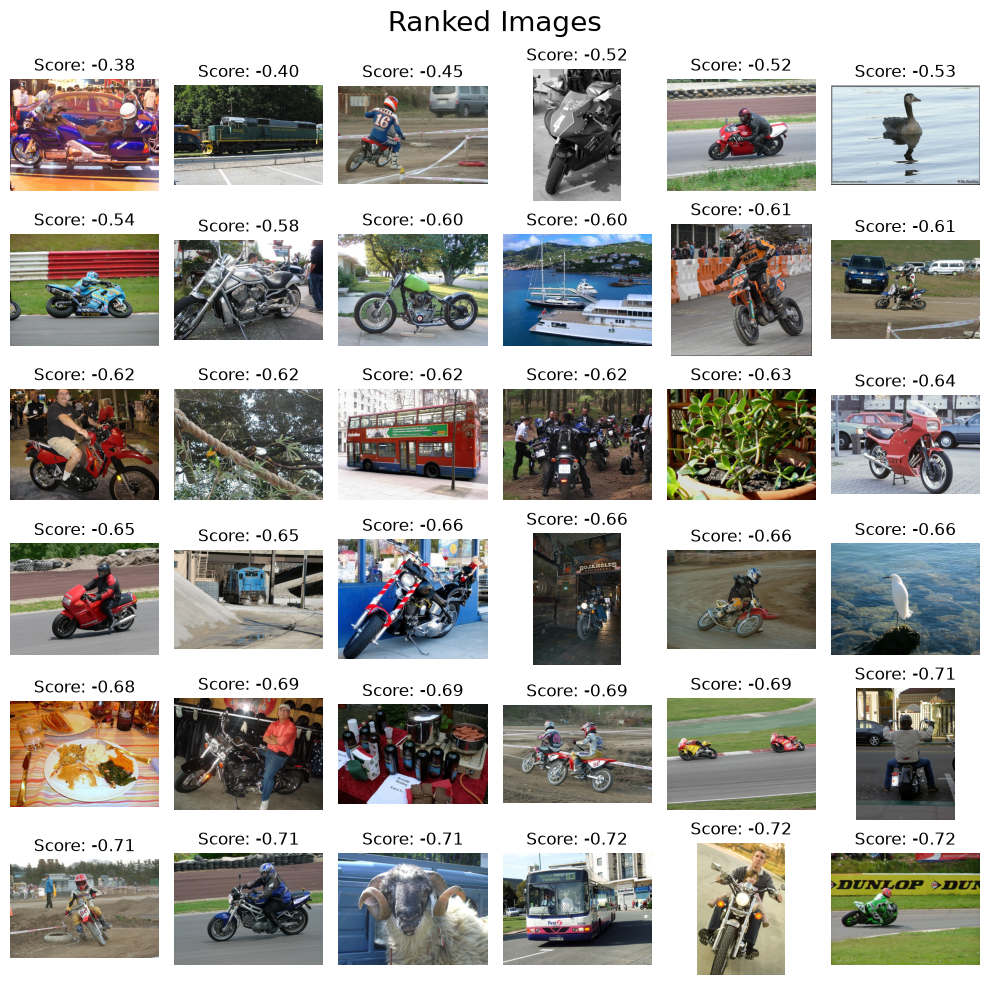

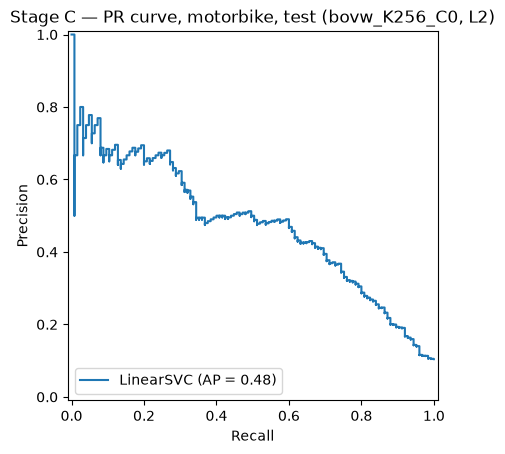

Average Precision (motorbike, test, L2 baseline) = 0.4759
  K=  5: P@K = 0.800   R@K = 0.032
  K= 10: P@K = 0.700   R@K = 0.056
  K= 20: P@K = 0.650   R@K = 0.104
  K= 50: P@K = 0.680   R@K = 0.272


In [8]:
# ── Stage C — motorbike test retrieval (baseline: L2) ─────────────────────────
x_te, y_te, names_te = get_xy('motorbike', ENC, 'test')
test_scores = W_b @ l2norm(x_te).T + b_b

top36 = np.argsort(test_scores)[::-1][:36]
print(f'Correctly retrieved in the top 36: {int((y_te[top36] > 0).sum())} / 36   '
      f'({int((y_te > 0).sum())} positives in {len(y_te)} test images)')
test_paths = [str(IMG_DIR / f'{n}.jpg') for n in names_te]
displayRankedImageList(test_scores, test_paths, uniform=False, figzize=(10, 10))
*_, ap_C = displayPrecisionRecallCurve(y_te, test_scores, title=f'Stage C — PR curve, motorbike, test ({ENC}, L2)')
print(f'Average Precision (motorbike, test, L2 baseline) = {ap_C:.4f}')
for k in (5, 10, 20, 50):
    print(f'  K={k:3d}: P@K = {compute_pk(y_te, test_scores, k):.3f}   R@K = {compute_rk(y_te, test_scores, k):.3f}')

## Stage D — Other categories

Same experiment for aeroplane, car, horse and person (one-vs-rest linear SVM, background as negatives, same splits and protocol).
$C$ selected **per category on validation**. Reported: per-class AP, mAP, PR curves, confusion matrices and precision/recall at threshold 0.

**Question:** how do intra-class variation, sample count, object scale and background diversity explain the AP differences?

BoVW bovw_K256_C0, 2x2 tiling, L2 — test AP (C chosen per class on validation):


,aeroplane,car,horse,motorbike,person,mAP
AP (test),0.5588,0.6878,0.5976,0.4759,0.7165,0.6073
C*,100.0,10.0,1.0,1.0,10.0,--


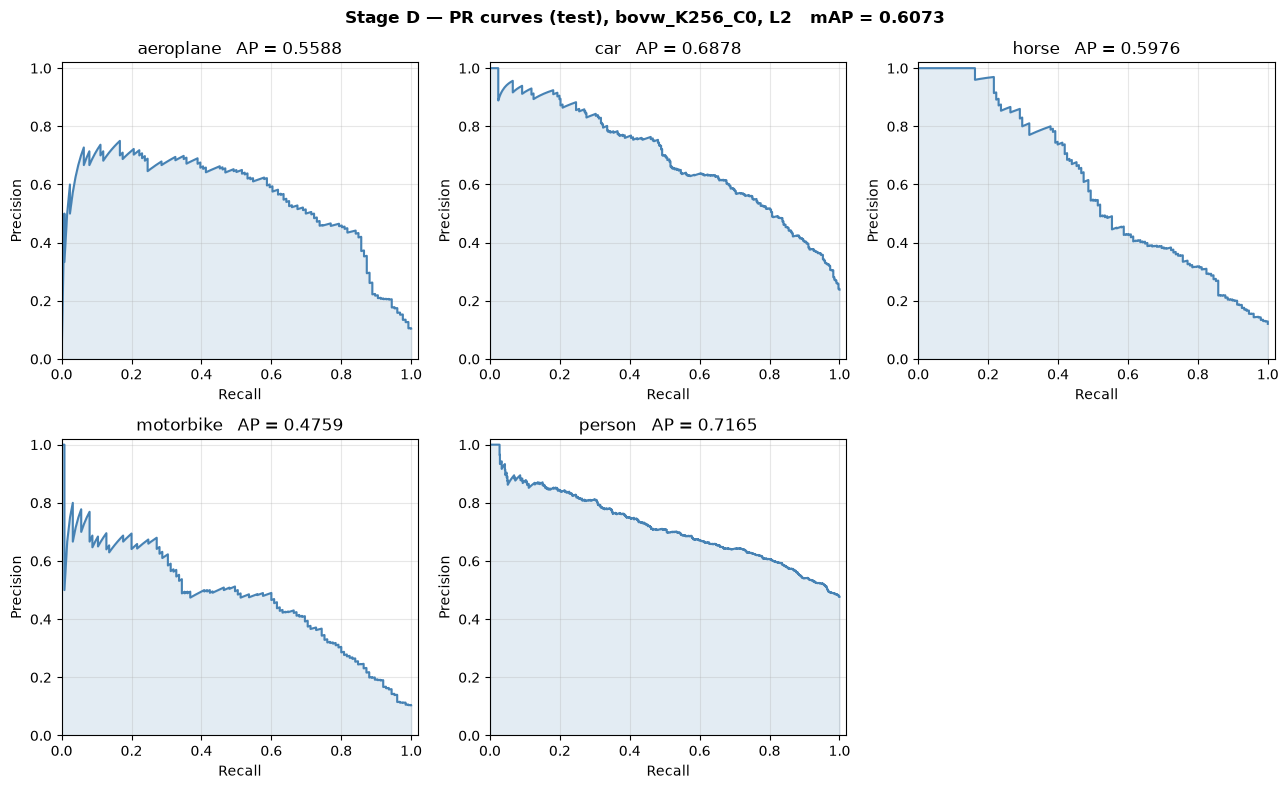

In [9]:
# ── Stage D — all categories, baseline L2 (test) ──────────────────────────────
ap_l2, svms_l2 = eval_all_cats(ENC, transform=l2norm, spatial=True)
print(f'BoVW {ENC}, 2x2 tiling, L2 — test AP (C chosen per class on validation):')
display(pd.DataFrame({'AP (test)': {k: round(v, 4) for k, v in ap_l2.items()},
                      'C*': {**{c: svms_l2[c]['C'] for c in CATEGORIES}, 'mAP': '--'}}).T)
pr_grid(svms_l2, ap_l2, f'Stage D — PR curves (test), {ENC}, L2')

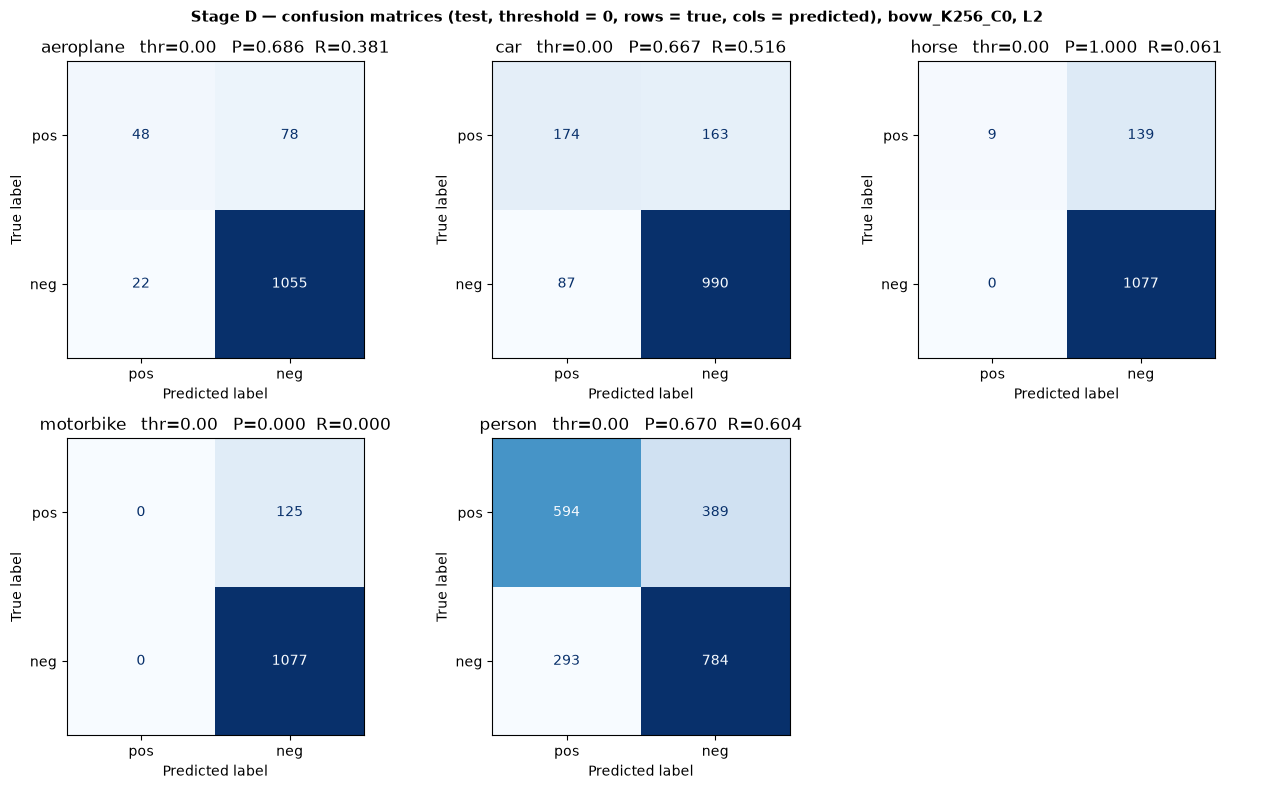

,thr,TP,FN,FP,TN,Precision,Recall,F1,Accuracy
category,,,,,,,,,
aeroplane,0.0,48,78,22,1055,0.6857,0.3810,0.4898,0.9169
car,0.0,174,163,87,990,0.6667,0.5163,0.5819,0.8232
horse,0.0,9,139,0,1077,1.0000,0.0608,0.1146,0.8865
motorbike,0.0,0,125,0,1077,0.0000,0.0000,0.0000,0.8960
person,0.0,594,389,293,784,0.6697,0.6043,0.6353,0.6689


In [10]:
# ── Stage D — confusion matrices and P/R at decision threshold 0 (test) ───────
def cm_grid(svms, title, thr=lambda cat: 0.0):
    # Confusion matrices + P/R/F1 per category at a per-category decision threshold.
    fig, axes = plt.subplots(2, 3, figsize=(13, 8)); axes = axes.flatten()
    rows = []
    for ax, cat in zip(axes, CATEGORIES):
        t = thr(cat); m = thr_metrics(svms[cat]['y'], svms[cat]['scores'], thr=t)
        ConfusionMatrixDisplay(np.array([[m['TP'], m['FN']], [m['FP'], m['TN']]]),
                               display_labels=['pos', 'neg']).plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(f'{cat}   thr={t:.2f}   P={m["Precision"]:.3f}  R={m["Recall"]:.3f}')
        rows.append({'category': cat, 'thr': round(t, 3),
                     **{k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()}})
    axes[-1].axis('off')
    fig.suptitle(title, fontsize=11, fontweight='bold'); plt.tight_layout(); plt.show()
    return pd.DataFrame(rows).set_index('category')

df_l2_thr0 = cm_grid(svms_l2, f'Stage D — confusion matrices (test, threshold = 0, rows = true, cols = predicted), {ENC}, L2')
display(df_l2_thr0)

## Stage E — Normalization and spatial information

Compare no normalization, L1 and L2 normalization of the BoVW histograms, each with the single global histogram and the 2×2 spatial representation
(motorbike, validation AP, $C$ swept for every combination). The Hellinger map is added in Stage F and the final choice is made at the end of Stage F.

**Questions:** effect of L2 normalization on the self-similarity $K(\mathbf h,\mathbf h)$ under a linear kernel; what can be inferred from it; how does it compare with $K(\mathbf h,\mathbf h')$;
does the same hold for unnormalized / L1 histograms; is normalization related to classification performance; why can removing spatial information help some classes and hurt others?

In [11]:
# ── Stage E — self-similarity under a linear kernel (numeric check, validation images) ──
x_chk = x_va
print('Linear-kernel similarities on validation images (mean over images / pairs):')
print(f'{"normalization":>14} | {"K(h,h)":>10} | {"K(h,h2)":>10} | {"max K(h,h2)":>12}')   # h2 = a different image h\'
for name, tf in [('none', identity), ('L1', l1norm), ('L2', l2norm)]:
    h = tf(x_chk); G = h @ h.T
    off = G[~np.eye(len(G), dtype=bool)]
    print(f'{name:>14} | {np.mean(np.diag(G)):10.4f} | {off.mean():10.4f} | {off.max():12.4f}')

Linear-kernel similarities on validation images (mean over images / pairs):
 normalization |     K(h,h) |    K(h,h2) |  max K(h,h2)
          none | 27008692.2588 | 9097457.3811 | 213604347.0000
            L1 |     0.0174 |     0.0059 |       0.1440
            L2 |     1.0000 |     0.3613 |       0.9866


spatial,global,tiling 2x2
norm,,
No norm,0.2743,0.4172
L1,0.3715,0.4707
L2,0.3939,0.5901


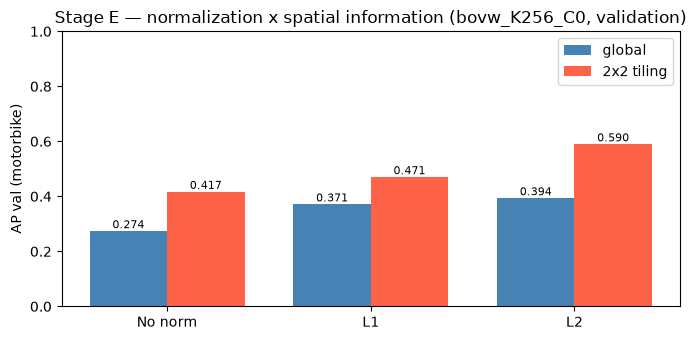

In [12]:
# ── Stage E — normalization x spatial information (validation, motorbike) ─────
TRANSFORMS = {'No norm': identity, 'L1': l1norm, 'L2': l2norm}   # Hellinger variants added in Stage F
norm_val = {}                     # (norm, spatial) -> {'ap', 'C'}

def run_norm_grid(names):
    for name in names:
        for spatial in (False, True):
            xt, yt, _ = get_xy('motorbike', ENC, 'train', spatial)
            xv, yv, _ = get_xy('motorbike', ENC, 'val', spatial)
            res = sweep_c(xt, yt, xv, yv, TRANSFORMS[name]); c = best_c(res)
            norm_val[(name, spatial)] = {'ap': res[c], 'C': c}

def show_norm_grid(names, title):
    df = pd.DataFrame([{'norm': n, 'spatial': 'tiling 2x2' if s else 'global',
                        'AP val': round(norm_val[(n, s)]['ap'], 4), 'C*': norm_val[(n, s)]['C']}
                       for n in names for s in (False, True)])
    display(df.pivot(index='norm', columns='spatial', values='AP val').loc[names])
    fig, ax = plt.subplots(figsize=(7, 3.5)); w = 0.38; xs = np.arange(len(names))
    for j, (s, lab, col) in enumerate([(False, 'global', 'steelblue'), (True, '2x2 tiling', 'tomato')]):
        v = [norm_val[(n, s)]['ap'] for n in names]
        ax.bar(xs + (j - 0.5) * w, v, w, label=lab, color=col)
        for x, y in zip(xs + (j - 0.5) * w, v): ax.text(x, y + 0.01, f'{y:.3f}', ha='center', fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(names); ax.set_ylim(0, 1); ax.set_ylabel('AP val (motorbike)')
    ax.set_title(title); ax.legend(); plt.tight_layout(); plt.show()

run_norm_grid(list(TRANSFORMS))
show_norm_grid(list(TRANSFORMS), f'Stage E — normalization x spatial information ({ENC}, validation)')

## Stage F — Hellinger feature map

The Hellinger (Bhattacharyya) kernel $K(\mathbf h,\mathbf h')=\sum_i\sqrt{h_ih'_i}$ is a linear kernel on the explicit feature map $\sqrt{\mathbf h}$ (non-negative, L1-normalized $\mathbf h$).
Implementation: **L1 → square root (→ L2)**, a one-line change applied to train, validation and test histograms.
For an L1-normalized $\mathbf h$, $\lVert\sqrt{\mathbf h}\rVert_2^2=\sum_i h_i=1$, so the final L2 step is redundant (a numerical no-op).
Because the handout asks about the *order* of normalization and square root, the experiment below compares all orders explicitly
(it also separates "square root alone" from "square root of an L1-normalized histogram", which differ by a per-image scale factor, not by an L2 step).
$C$ is re-selected on validation for every variant.

**Questions:** how should the histograms be normalized for the Hellinger classifier, and before or after the square root; why does the square root change the relative contribution of frequent and rare words?

spatial,global,tiling 2x2
norm,,
No norm,0.2743,0.4172
L1,0.3715,0.4707
L2,0.3939,0.5901
sqrt only,0.3645,0.6000
Hellinger (L1-sqrt-L2),0.4789,0.7831


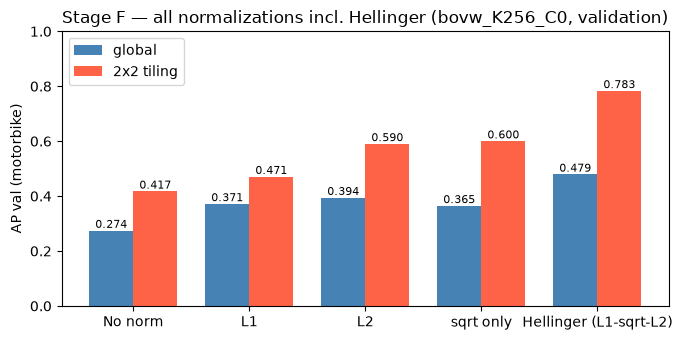


Selected on validation: norm = Hellinger (L1-sqrt-L2), spatial = 2x2 tiling, AP val = 0.7831


In [13]:
# ── Stage F — Hellinger feature map (validation, motorbike) ───────────────────
TRANSFORMS.update({'sqrt only': sqrt_only, 'Hellinger (L1-sqrt-L2)': hellinger})
run_norm_grid(['sqrt only', 'Hellinger (L1-sqrt-L2)'])
show_norm_grid(list(TRANSFORMS), f'Stage F — all normalizations incl. Hellinger ({ENC}, validation)')

# ── Selection on validation ───────────────────────────────────────────────────
(NORM, SPATIAL) = max(norm_val, key=lambda key: norm_val[key]['ap'])
TF = TRANSFORMS[NORM]
print(f'\nSelected on validation: norm = {NORM}, spatial = {"2x2 tiling" if SPATIAL else "global"}, '
      f'AP val = {norm_val[(NORM, SPATIAL)]["ap"]:.4f}')

In [14]:
# ── Stage F — order of square root and normalizations (validation, motorbike, tiling) ──
ORDER = {'sqrt only (no normalization)': sqrt_only,
         'L1 -> sqrt':                   lambda x: np.sqrt(l1norm(x)),
         'L1 -> sqrt -> L2 (Hellinger)': hellinger,
         'sqrt -> L2':                   lambda x: l2norm(np.sqrt(x)),
         'L2 -> sqrt':                   lambda x: np.sqrt(l2norm(x)),
         'L2 -> sqrt -> L2':             lambda x: l2norm(np.sqrt(l2norm(x)))}
xt, yt, _ = get_xy('motorbike', ENC, 'train'); xv, yv, _ = get_xy('motorbike', ENC, 'val')
rows = []
for name, f in ORDER.items():
    res = sweep_c(xt, yt, xv, yv, f); c = best_c(res)
    rows.append({'pipeline': name, 'AP val': round(res[c], 4), 'C*': c,
                 'mean L2 norm of features (val)': round(float(np.linalg.norm(f(xv), axis=1).mean()), 3)})
display(pd.DataFrame(rows).set_index('pipeline'))
print('Identical rows = mathematically equivalent pipelines; L2 after L1->sqrt does not change anything.')

,AP val,C*,mean L2 norm of features (val)
pipeline,,,
sqrt only (no normalization),0.6000,0.001,197.324
L1 -> sqrt,0.7831,1.000,1.000
L1 -> sqrt -> L2 (Hellinger),0.7831,1.000,1.000
sqrt -> L2,0.7831,1.000,1.000
L2 -> sqrt,0.7910,1.000,3.234
L2 -> sqrt -> L2,0.7831,1.000,1.000


Identical rows = mathematically equivalent pipelines; L2 after L1->sqrt does not change anything.


In [15]:
# ── Stage E/F — ranking quality (AP) vs classification at the fixed threshold 0 (validation, motorbike, tiling) ──
rows = []
xt, yt, _ = get_xy('motorbike', ENC, 'train'); xv, yv, _ = get_xy('motorbike', ENC, 'val')
for name, tf in TRANSFORMS.items():
    c = norm_val[(name, True)]['C']
    W, b = utils.train_svm(tf(xt), yt, C=c, seed=SEED); m = thr_metrics(yv, W @ tf(xv).T + b)
    rows.append({'norm': name, 'AP val': round(norm_val[(name, True)]['ap'], 4), 'C*': c,
                 'Precision@0': round(m['Precision'], 3), 'Recall@0': round(m['Recall'], 3),
                 'F1@0': round(m['F1'], 3), 'Accuracy@0': round(m['Accuracy'], 3)})
display(pd.DataFrame(rows).set_index('norm'))
print('AP scores the whole ranking; precision/recall/F1 at threshold 0 score one operating point. They need not improve together.')

,AP val,C*,Precision@0,Recall@0,F1@0,Accuracy@0
norm,,,,,,
No norm,0.4172,0.001,0.480,0.500,0.490,0.890
L1,0.4707,100.000,0.000,0.000,0.000,0.895
L2,0.5901,1.000,0.000,0.000,0.000,0.895
sqrt only,0.6000,0.001,0.556,0.625,0.588,0.908
Hellinger (L1-sqrt-L2),0.7831,1.000,0.000,0.000,0.000,0.895


AP scores the whole ranking; precision/recall/F1 at threshold 0 score one operating point. They need not improve together.


In [16]:
# ── Stage E (per category) — global vs 2x2 tiling on validation, for L2 and for the selected normalization ──
rows = []
for nm, tf in [('L2', l2norm), (NORM, TF)]:
    for sp in (False, True):
        r = {}
        for cat in CATEGORIES:
            xt, yt, _ = get_xy(cat, ENC, 'train', sp); xv, yv, _ = get_xy(cat, ENC, 'val', sp)
            res = sweep_c(xt, yt, xv, yv, tf); r[cat] = round(res[best_c(res)], 3)
        rows.append({'norm': nm, 'spatial': 'tiling 2x2' if sp else 'global', **r, 'mean': round(float(np.mean(list(r.values()))), 3)})
display(pd.DataFrame(rows).set_index(['norm', 'spatial']))

aeroplane    car  horse  motorbike  person   mean
norm                   spatial                                                      
L2                     global          0.531  0.599  0.568      0.394   0.656  0.550
                       tiling 2x2      0.607  0.662  0.626      0.590   0.691  0.635
Hellinger (L1-sqrt-L2) global          0.879  0.637  0.522      0.479   0.680  0.639
                       tiling 2x2      0.883  0.753  0.659      0.783   0.759  0.767

FINAL BoVW: bovw_K256_C0, Hellinger (L1-sqrt-L2), tiling — test AP


,aeroplane,car,horse,motorbike,person,mAP
L2 baseline (Stage D),0.5588,0.6878,0.5976,0.4759,0.7165,0.6073
final: Hellinger (L1-sqrt-L2),0.6991,0.7383,0.6426,0.6078,0.7613,0.6898


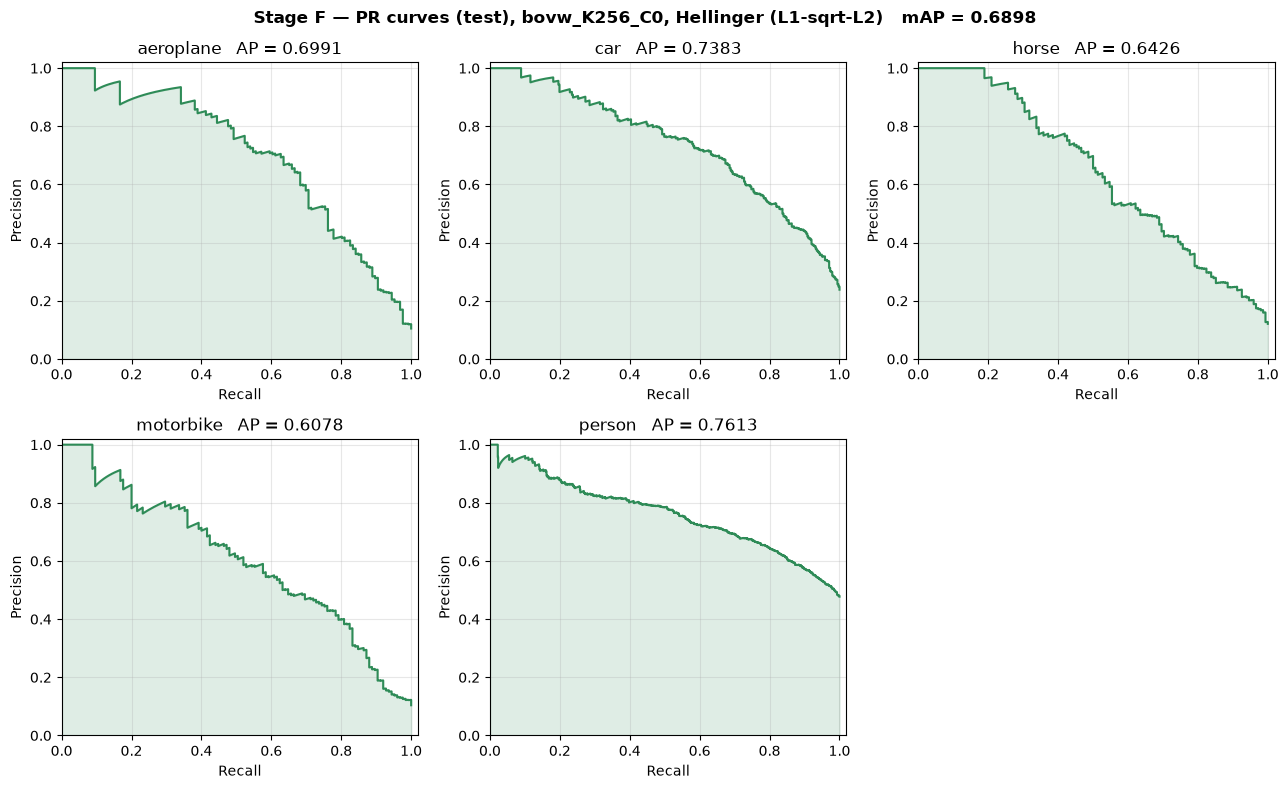

Motorbike (test), final config:
  K=  5: P@K = 1.000   R@K = 0.040
  K= 10: P@K = 1.000   R@K = 0.080
  K= 20: P@K = 0.900   R@K = 0.144
  K= 50: P@K = 0.780   R@K = 0.312


In [17]:
# ── Stage F — final BoVW configuration evaluated on test (all categories) ────
ap_bovw, svms_bovw = eval_all_cats(ENC, transform=TF, spatial=SPATIAL)
print(f'FINAL BoVW: {ENC}, {NORM}, {"tiling" if SPATIAL else "global"} — test AP')
display(ap_table({'L2 baseline (Stage D)': ap_l2, f'final: {NORM}': ap_bovw}))
pr_grid(svms_bovw, ap_bovw, f'Stage F — PR curves (test), {ENC}, {NORM}', color='seagreen')

sm = svms_bovw['motorbike']
print('Motorbike (test), final config:')
for k in (5, 10, 20, 50):
    print(f'  K={k:3d}: P@K = {compute_pk(sm["y"], sm["scores"], k):.3f}   R@K = {compute_rk(sm["y"], sm["scores"], k):.3f}')

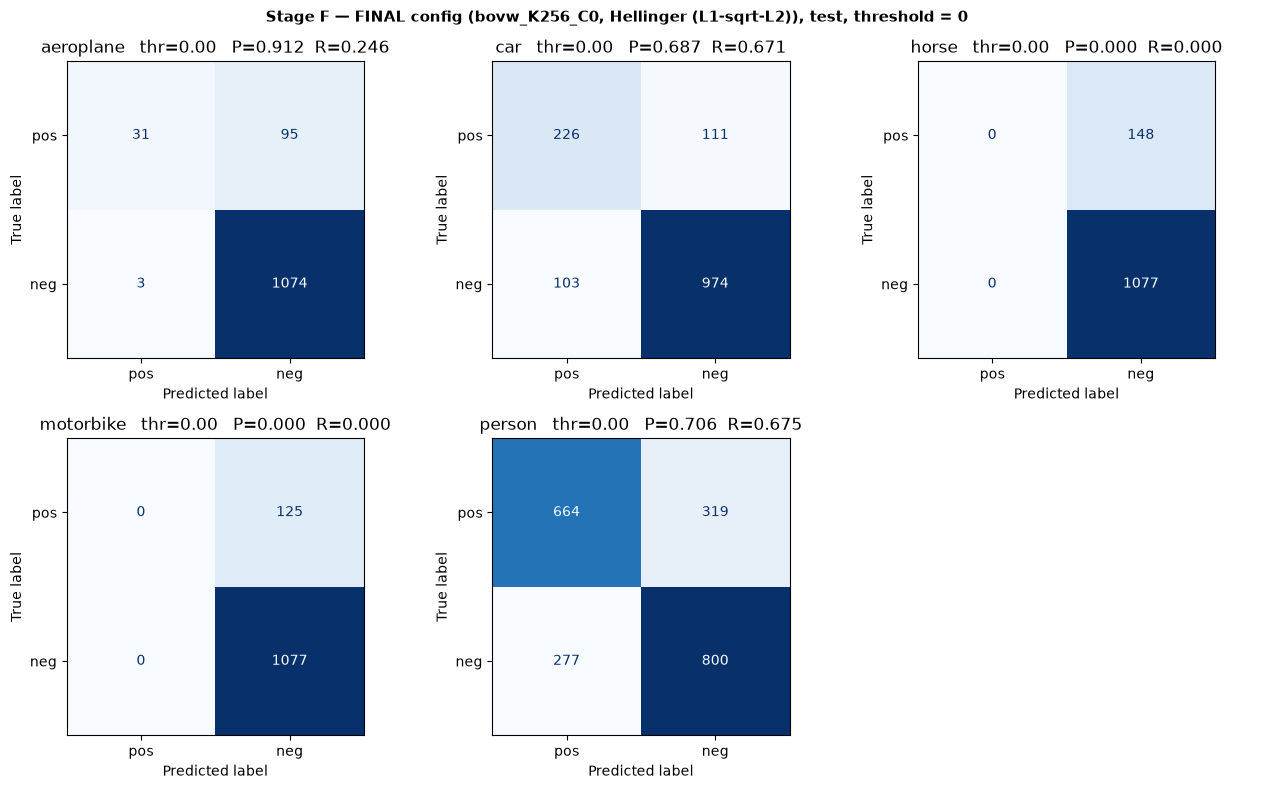

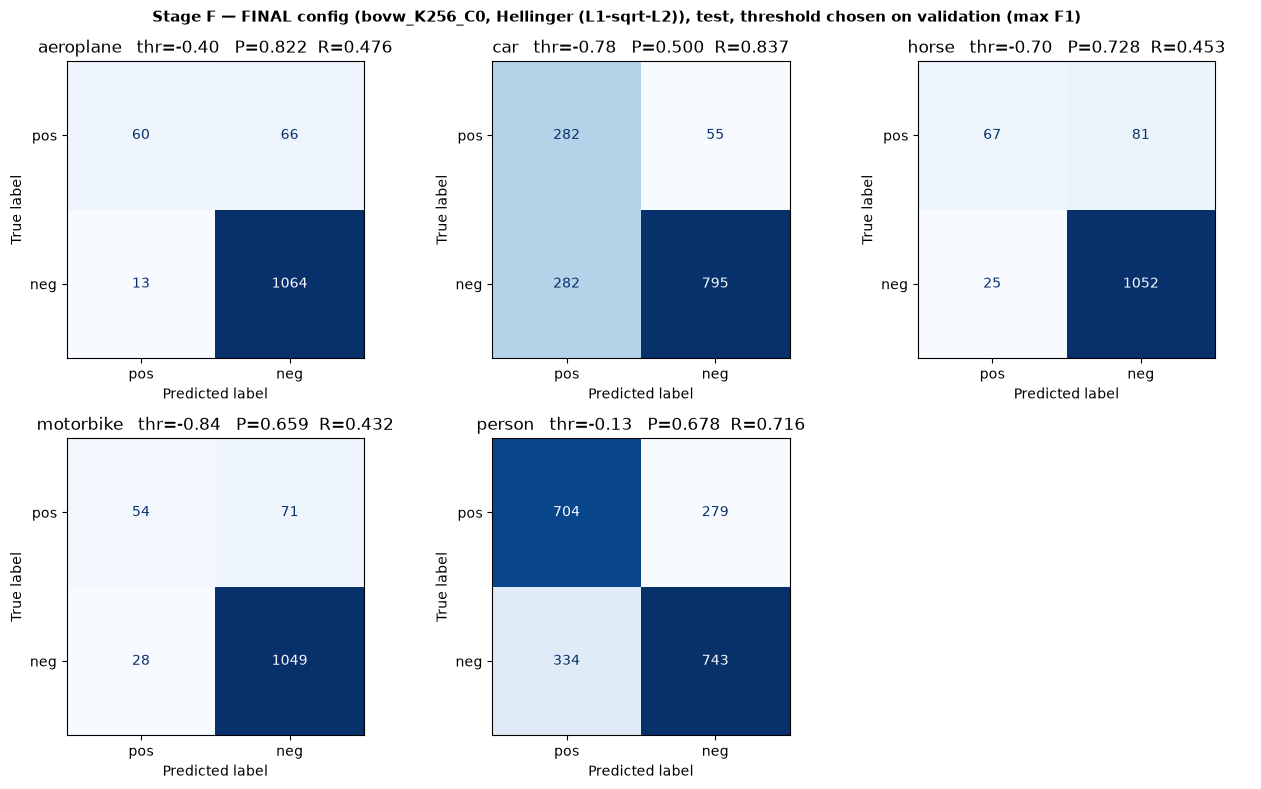

,Recall L2 thr0,Recall final thr0,Recall final val-thr,F1 L2 thr0,F1 final thr0,F1 final val-thr
category,,,,,,
aeroplane,0.381,0.246,0.476,0.490,0.388,0.603
car,0.516,0.671,0.837,0.582,0.679,0.626
horse,0.061,0.000,0.453,0.115,0.000,0.558
motorbike,0.000,0.000,0.432,0.000,0.000,0.522
person,0.604,0.676,0.716,0.635,0.690,0.697


In [18]:
# ── Stage F — confusion matrices / P-R for the FINAL configuration (test) ────
def val_thr(cat):
    # Threshold maximising F1 on the VALIDATION set (never on test).
    xv, yv, _ = get_xy(cat, ENC, 'val', SPATIAL)
    s = svms_bovw[cat]['W'] @ TF(xv).T + svms_bovw[cat]['b']
    cand = np.unique(s)
    f1s = [f1_score(yv, np.where(s >= t, 1, -1), pos_label=1, zero_division=0) for t in cand]
    return float(cand[int(np.argmax(f1s))])

df_f0 = cm_grid(svms_bovw, f'Stage F — FINAL config ({ENC}, {NORM}), test, threshold = 0')
df_fv = cm_grid(svms_bovw, f'Stage F — FINAL config ({ENC}, {NORM}), test, threshold chosen on validation (max F1)', thr=val_thr)
display(pd.DataFrame({'Recall  L2 thr0': df_l2_thr0['Recall'], 'Recall  final thr0': df_f0['Recall'], 'Recall  final val-thr': df_fv['Recall'],
                      'F1  L2 thr0': df_l2_thr0['F1'], 'F1  final thr0': df_f0['F1'], 'F1  final val-thr': df_fv['F1']}).round(3))

## Stage G — Vary the number of training images

Train with 10 %, 25 %, 50 % and 100 % of the labelled training set (stratified random subsampling, seeds 0 / 42 / 123, mean ± std) and plot **validation** AP
against the number of training images, for the L2 baseline (linear kernel) and for the selected setting from Stage F (Hellinger map if selected).
$K$, spatial representation and $C$ are the validation-selected values of Stages A–F (selected with the *full* training set) and are kept **fixed** across fractions,
which isolates the effect of the amount of data; re-tuning $C$ on a validation set with ≈ 9 positives (10 %) would be unreliable. At 100 % the std only reflects the SVM's internal shuffling (the subsample is the whole set), not variability of the training sample.

**Questions:** performance with the linear vs the Hellinger kernel; does it saturate, and would more examples or more diversity help?


L2 (linear kernel)  (C = 1.0, tiling)
   10%  n =   90: AP val = 0.2998 +/- 0.0484
   25%  n =  227: AP val = 0.3581 +/- 0.0297
   50%  n =  455: AP val = 0.4372 +/- 0.0703
  100%  n =  911: AP val = 0.5899 +/- 0.0007

Hellinger (L1-sqrt-L2) (selected)  (C = 1.0, tiling)
   10%  n =   90: AP val = 0.2680 +/- 0.0321
   25%  n =  227: AP val = 0.4452 +/- 0.0254
   50%  n =  455: AP val = 0.5648 +/- 0.0563
  100%  n =  911: AP val = 0.7836 +/- 0.0008


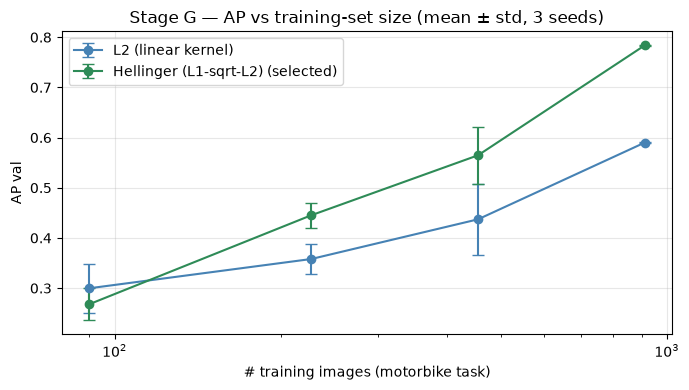

In [19]:
# ── Stage G — AP vs number of training images (validation, motorbike, 3 seeds) ──
FRACS, SEEDS_FR = [0.10, 0.25, 0.50, 1.00], [0, 42, 123]

def subsample_stratified(x, y, frac, seed):
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y > 0)[0], np.where(y < 0)[0]
    sel = np.concatenate([rng.choice(pos, max(1, int(len(pos) * frac)), replace=False),
                          rng.choice(neg, max(1, int(len(neg) * frac)), replace=False)])
    return x[sel], y[sel]

settings = {'L2 (linear kernel)': ('L2', True), f'{NORM} (selected)': (NORM, SPATIAL)}
frac_res = {}
for label, (nm, sp) in settings.items():
    tf, C = TRANSFORMS[nm], norm_val[(nm, sp)]['C']
    xt, yt, _ = get_xy('motorbike', ENC, 'train', sp)
    xv, yv, _ = get_xy('motorbike', ENC, 'val', sp)
    frac_res[label] = {}
    for frac in FRACS:
        aps = []
        for s in SEEDS_FR:
            xs, ys = subsample_stratified(xt, yt, frac, s)
            W, b = utils.train_svm(tf(xs), ys, C=C, seed=s)
            aps.append(compute_ap(yv, W @ tf(xv).T + b))
        n = len(subsample_stratified(xt, yt, frac, 0)[1])
        frac_res[label][frac] = {'n': n, 'mean': float(np.mean(aps)), 'std': float(np.std(aps))}
    print(f'\n{label}  (C = {C}, {"tiling" if sp else "global"})')
    for frac in FRACS:
        r = frac_res[label][frac]; print(f'  {int(frac*100):3d}%  n = {r["n"]:4d}: AP val = {r["mean"]:.4f} +/- {r["std"]:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
for (label, fr), col in zip(frac_res.items(), ['steelblue', 'seagreen']):
    ns = [fr[f]['n'] for f in FRACS]
    ax.errorbar(ns, [fr[f]['mean'] for f in FRACS], yerr=[fr[f]['std'] for f in FRACS],
                fmt='o-', ms=6, capsize=4, color=col, label=label)
ax.set_xscale('log'); ax.set_xlabel('# training images (motorbike task)'); ax.set_ylabel('AP val')
ax.set_title('Stage G — AP vs training-set size (mean ± std, 3 seeds)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
# Part 2 — Advanced encodings: VLAD and Fisher Vectors

Same local descriptors, same splits, same linear SVM protocol. Provided encoders (SIFT → PCA to $D=80$, $K=32$, 2×2 tiling):
`vlad_K32_C80` and `fv_K32_C80`. Normalization: L2 (the optional intra-normalization is not applied); $C$ chosen on validation (per category).

## Stage H — VLAD

VLAD (first-order encoding) sums, per Voronoi cell, the residuals between the descriptors and their centre: $K\times D$ values per tile.
With tiling: $4\times K\times D = 4\times32\times80 = 10240$ dimensions. The BoVW encoding of Part 1 is replaced by VLAD and the classification/retrieval experiments are repeated.

**Question:** compare the nominal dimensions of BoVW ($K$) and VLAD ($K\times D$); what changes in capacity and storage?

VLAD dimension: 10240  (= 4 tiles x 32 centres x 80 dims)


,aeroplane,car,horse,motorbike,person,mAP
AP (test),0.7482,0.7656,0.6825,0.6902,0.7484,0.727
C*,1.0,1.0,0.1,1.0,10.0,--


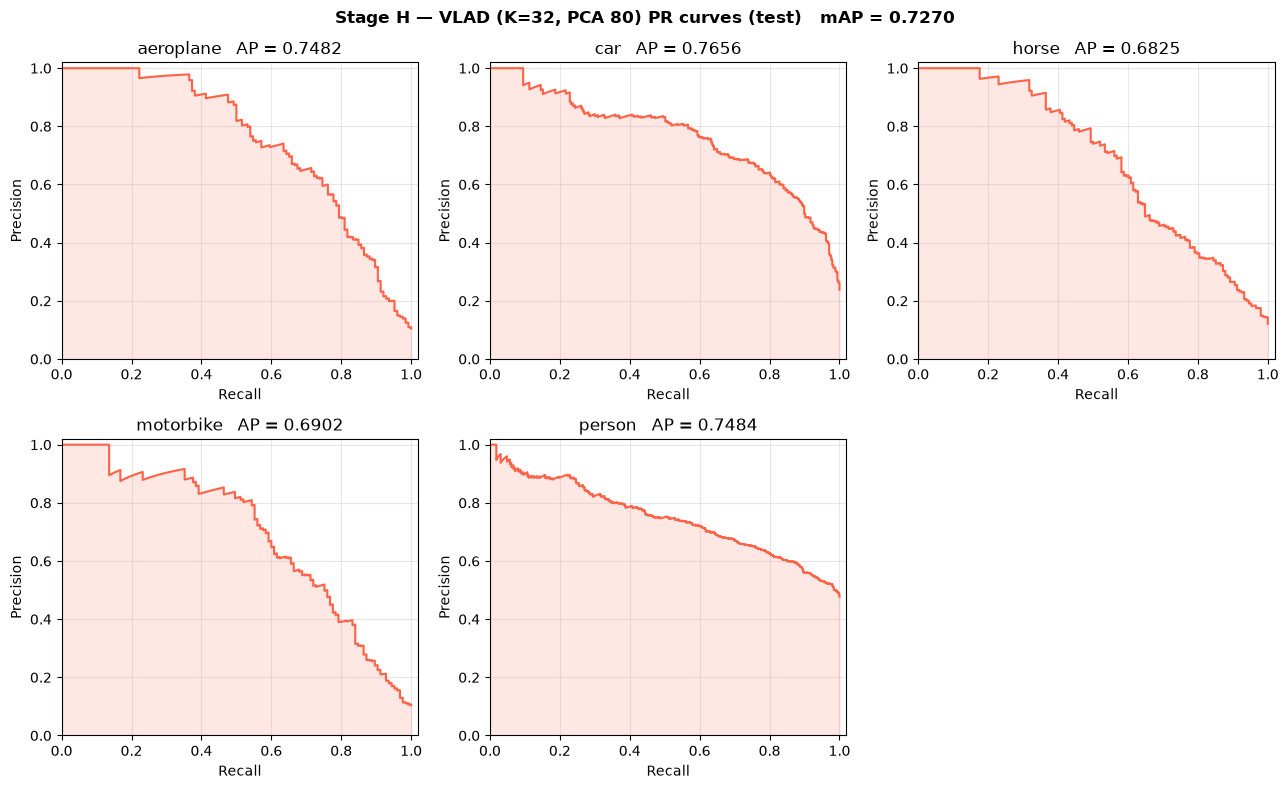

Ranked TEST images — motorbike (VLAD):


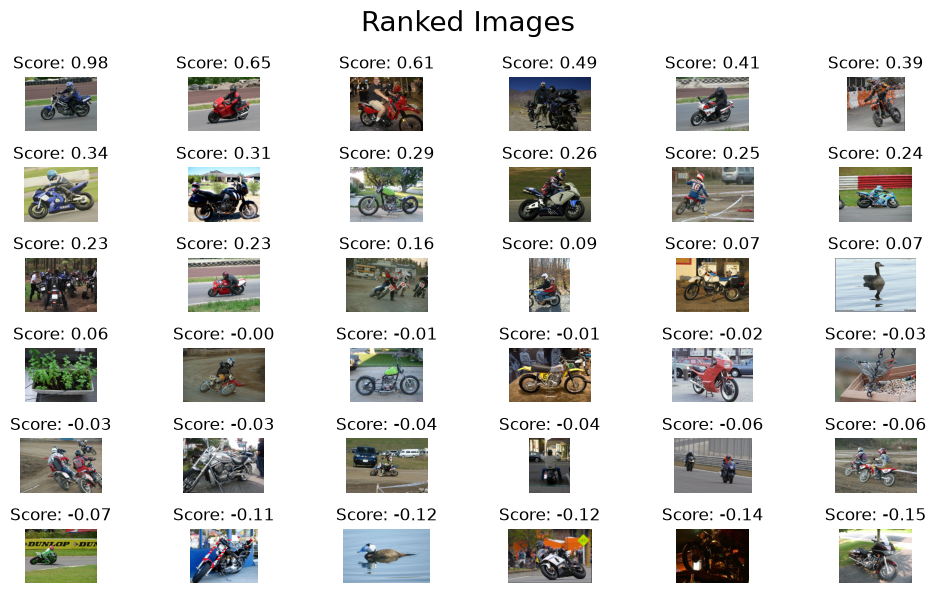

In [20]:
# ── Stage H — VLAD (test, all categories) ─────────────────────────────────────
ENC_VLAD = 'vlad_K32_C80'
dim_vlad = load_enc('motorbike', ENC_VLAD, 'train')[0].shape[1]
print(f'VLAD dimension: {dim_vlad}  (= 4 tiles x 32 centres x 80 dims)')
ap_vlad, svms_vlad = eval_all_cats(ENC_VLAD, transform=l2norm, spatial=True)
display(pd.DataFrame({'AP (test)': {k: round(v, 4) for k, v in ap_vlad.items()},
                      'C*': {**{c: svms_vlad[c]['C'] for c in CATEGORIES}, 'mAP': '--'}}).T)
pr_grid(svms_vlad, ap_vlad, 'Stage H — VLAD (K=32, PCA 80) PR curves (test)', color='tomato')

sv = svms_vlad['motorbike']
print('Ranked TEST images — motorbike (VLAD):')
displayRankedImageList(sv['scores'], [str(IMG_DIR / f'{n}.jpg') for n in sv['names']], uniform=False, figzize=(10, 6))

## Stage I — Fisher Vector

The Fisher Vector (second-order) uses a diagonal-covariance GMM (fitted on training descriptors only) and encodes first- and second-order statistics (mean and variance gradients) per mixture component:
$2KD$ values for the mean and variance gradients, **plus $K$ values for the gradient w.r.t. the mixture weights** in this implementation: `skimage.feature.fisher_vector` returns $2KD+K=5152$ numbers per tile (the handout's $2Kd$ counts only the mean and variance parts), i.e. $4\times5152=20608$ for 2×2 tiling. The dimension is therefore not forced to 20480; it is checked against the stored encodings below (the docstring of `FisherVectorEncoder` in `src/encoders.py` mentions only $2GC$ and is out of date). `improved=False` (default): no power/L2 normalization inside the encoder.
Same classifier, splits and protocol as BoVW and VLAD; AP/mAP, dimension, extraction time and storage are compared below.

**Question:** what additional information does the FV encode compared with VLAD, and which computational costs does it introduce?

FV dimension: 20608  (= 4 tiles x (2 x 32 x 80 + 32))


,aeroplane,car,horse,motorbike,person,mAP
AP (test),0.7056,0.7581,0.6974,0.6754,0.7591,0.7191
C*,100.0,10.0,1.0,10.0,100.0,--


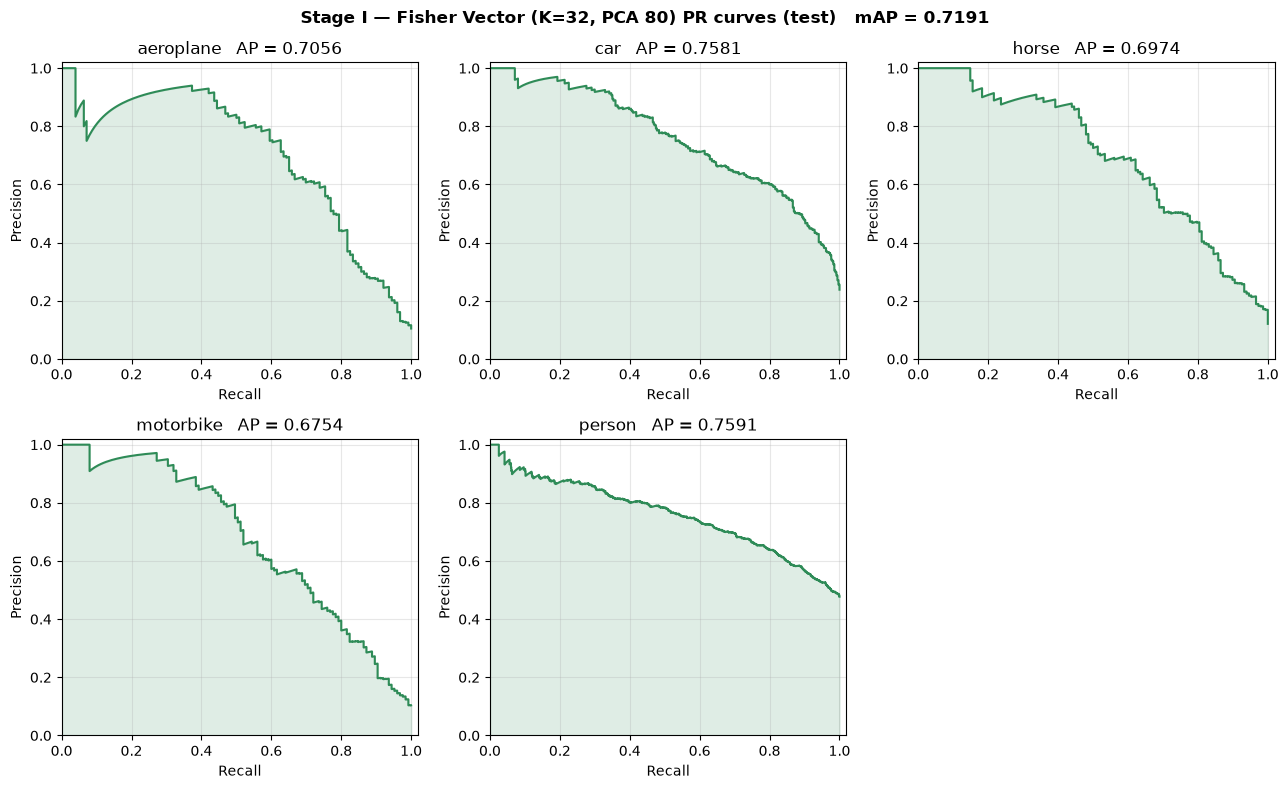

Ranked TEST images — motorbike (FV):


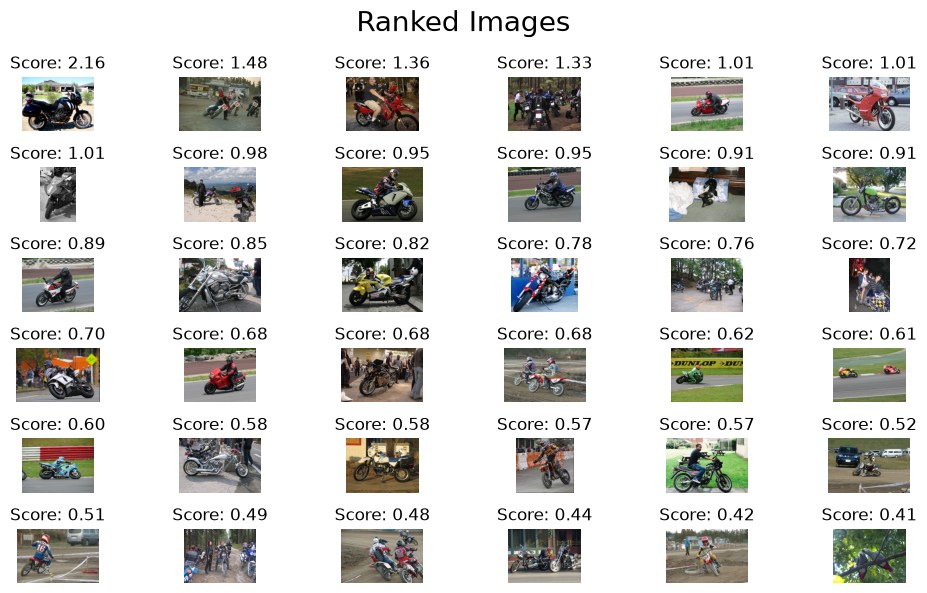

In [21]:
# ── Stage I — Fisher Vector (test, all categories) ────────────────────────────
ENC_FV = 'fv_K32_C80'
dim_fv = load_enc('motorbike', ENC_FV, 'train')[0].shape[1]
assert dim_fv == 4 * (2 * 32 * 80 + 32), dim_fv   # 2KD (means, variances) + K (weights), per tile
print(f'FV dimension: {dim_fv}  (= 4 tiles x (2 x 32 x 80 + 32))')
ap_fv, svms_fv = eval_all_cats(ENC_FV, transform=l2norm, spatial=True)
display(pd.DataFrame({'AP (test)': {k: round(v, 4) for k, v in ap_fv.items()},
                      'C*': {**{c: svms_fv[c]['C'] for c in CATEGORIES}, 'mAP': '--'}}).T)
pr_grid(svms_fv, ap_fv, 'Stage I — Fisher Vector (K=32, PCA 80) PR curves (test)', color='seagreen')

sf = svms_fv['motorbike']
print('Ranked TEST images — motorbike (FV):')
displayRankedImageList(sf['scores'], [str(IMG_DIR / f'{n}.jpg') for n in sf['names']], uniform=False, figzize=(10, 6))

### Comparison: BoVW vs VLAD vs Fisher Vector

Same splits, same classifier (linear SVM, $C$ per category on validation), test set. Both BoVW rows are shown: the L2 baseline (isolates the effect of the **encoding**)
and the final Stage F setting. Encoding time per image = dense SIFT + descriptor PCA + encoding with the encoder already loaded, mean over 50 test images (CPU, includes image reading and resizing; run-to-run variation is expected).

,aeroplane,car,horse,motorbike,person,mAP,Dim,Encode (ms/img),"SVM train, 5 cls (s)",Inference (us/img),Feature storage (KB/img)
Method,,,,,,,,,,,
BoVW K=256 L2 (baseline),0.5588,0.6878,0.5976,0.4759,0.7165,0.6073,1024,789,0.44,12.1,4.0
BoVW K=256 Hellinger (L1-sqrt-L2) (final),0.6991,0.7383,0.6426,0.6078,0.7613,0.6898,1024,789,0.44,16.3,4.0
"VLAD K=32, PCA 80, L2",0.7482,0.7656,0.6825,0.6902,0.7484,0.7270,10240,312,5.11,153.0,40.0
"FV K=32, PCA 80, L2",0.7056,0.7581,0.6974,0.6754,0.7591,0.7191,20608,467,20.27,146.4,80.5


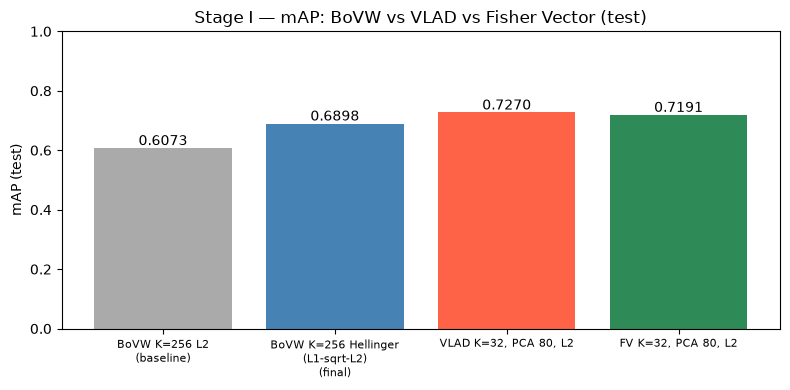

Storage = ESTIMATE: float32 feature vector per image (dim x 4 bytes), not the size of the .npz files. Inference = scoring + normalization of the test set, 5 classifiers.

Motorbike retrieval on the test set (125 positives in 1202 images):


,P@5,P@10,P@20,P@50,P@100,R@20,R@50,R@100
Method,,,,,,,,
BoVW K=256 L2 (baseline),0.8,0.7,0.65,0.68,0.49,0.104,0.272,0.392
BoVW K=256 Hellinger (L1-sqrt-L2) (final),1.0,1.0,0.90,0.78,0.62,0.144,0.312,0.496
"VLAD K=32, PCA 80, L2",1.0,1.0,0.90,0.88,0.71,0.144,0.352,0.568
"FV K=32, PCA 80, L2",1.0,1.0,0.95,0.88,0.66,0.152,0.352,0.528


In [22]:
# ── Stage I — comparison table, timings, storage ─────────────────────────────
dim_bovw = load_enc('motorbike', ENC, 'train')[0].shape[1] // (1 if SPATIAL else 4)
methods = {
    f'BoVW K={K_BEST} L2 (baseline)':            dict(aps=ap_l2,   svms=svms_l2,   enc=ENC,      dim=load_enc('motorbike', ENC, 'train')[0].shape[1]),
    f'BoVW K={K_BEST} {NORM} (final)':            dict(aps=ap_bovw, svms=svms_bovw, enc=ENC,      dim=dim_bovw),
    'VLAD K=32, PCA 80, L2':                      dict(aps=ap_vlad, svms=svms_vlad, enc=ENC_VLAD, dim=dim_vlad),
    'FV K=32, PCA 80, L2':                        dict(aps=ap_fv,   svms=svms_fv,   enc=ENC_FV,   dim=dim_fv),
}

def encode_time_per_image(enc, n=50):
    e = encoders.ImageEncoder(str(ENC_DIR / f'{enc}.npz'))
    names = load_enc('motorbike', enc, 'test')[2][:n]
    paths = [str(IMG_DIR / f'{nm}.jpg') for nm in names]
    e.encode(paths[0])                                    # warm-up
    t0 = time.time()
    for p in paths: e.encode(p)
    return (time.time() - t0) / len(paths)

t_enc = {enc: encode_time_per_image(enc) for enc in (ENC, ENC_VLAD, ENC_FV)}
n_test_total = sum(len(svms_l2[c]['y']) for c in CATEGORIES)

rows = []
for name, m in methods.items():
    sv_ = m['svms']
    rows.append({'Method': name, **{c: f'{m["aps"][c]:.4f}' for c in CATEGORIES}, 'mAP': f'{m["aps"]["mAP"]:.4f}',
                 'Dim': m['dim'],
                 'Encode (ms/img)': f'{t_enc[m["enc"]]*1e3:.0f}',
                 'SVM train, 5 cls (s)': f'{sum(sv_[c]["t_train"] for c in CATEGORIES):.2f}',
                 'Inference (us/img)': f'{sum(sv_[c]["t_infer"] for c in CATEGORIES) / n_test_total * 1e6:.1f}',
                 'Feature storage (KB/img)': f'{m["dim"] * 4 / 1024:.1f}'})
df_cmp = pd.DataFrame(rows).set_index('Method')
display(df_cmp)

fig, ax = plt.subplots(figsize=(8, 4))
names_m = list(methods); maps = [methods[m]['aps']['mAP'] for m in names_m]
bars = ax.bar(range(len(names_m)), maps, color=['#aaaaaa', 'steelblue', 'tomato', 'seagreen'])
ax.set_xticks(range(len(names_m))); ax.set_xticklabels([n.replace(' (', '\n(') for n in names_m], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel('mAP (test)'); ax.set_title('Stage I — mAP: BoVW vs VLAD vs Fisher Vector (test)')
for bar, v in zip(bars, maps): ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.4f}', ha='center', fontsize=10)
plt.tight_layout(); plt.show()
print('Storage = ESTIMATE: float32 feature vector per image (dim x 4 bytes), not the size of the .npz files. Inference = scoring + normalization of the test set, 5 classifiers.')

# Retrieval quality for the target category (motorbike, test)
rows = []
for name, m in methods.items():
    q = m['svms']['motorbike']
    rows.append({'Method': name, **{f'P@{k}': round(compute_pk(q['y'], q['scores'], k), 3) for k in (5, 10, 20, 50, 100)},
                 **{f'R@{k}': round(compute_rk(q['y'], q['scores'], k), 3) for k in (20, 50, 100)}})
print('\nMotorbike retrieval on the test set (125 positives in 1202 images):')
display(pd.DataFrame(rows).set_index('Method'))

---
# Part 3 — Large visual vocabularies with PCA vs smaller vocabularies

## Stage A — Experimental design

| Condition | Codebook $K$ | PCA | Purpose | Implemented as |
|-----------|-------------|-----|---------|----------------|
| A | Small (256) | No | Low-cost baseline | BoVW K=256, 2×2 tiling (1024-d) |
| B | Large (1024) | No | High-capacity baseline | BoVW K=1024, 2×2 tiling (4096-d) |
| C | Large (1024) | Yes (128 / 256) | Compress richer representation | K=1024 tiling → normalization → PCA(128 / 256) |
| D | Match C's final dimension | No | Compare against a compact vocabulary | K=256 **global** histogram (256-d, matches PCA→256) |

K=512 (tiling) is added as an extra no-PCA reference. All conditions use the same normalization chosen in Stage F, the same splits and one-vs-rest linear SVMs
($C$ per category on validation). PCA is fitted on training images only, after normalization, with the L2/Hellinger-normalized vectors as input and no further normalization afterwards.
The BoVW histogram dimension is exactly $K$ (per tile); PCA output (128/256) is smaller than the number of input dimensions and than the number of training samples − 1.
Reported: test AP/mAP, accuracy and macro-F1 (one-vs-rest, decision threshold 0), original / final dimension, % of dimensions removed, PCA fitting time, SVM training time,
inference time per image and feature storage. **Limitation:** there is no precomputed K=128 encoding (extracting it from scratch is expensive), so PCA→128 has no exact-dimension counterpart; K=256 global (256-d) is the closest compact vocabulary and matches PCA→256 exactly. Codebook fitting and encoding times were measured offline, not re-timed; only SVM/PCA seed 42 is used (no resampling of the vocabulary).

In [23]:
# ── Part 3 — conditions A-D ──────────────────────────────────────────────────
from sklearn.decomposition import PCA as SkPCA

def run_condition(cond, label, k, spatial, pca_d=None):
    enc = ensure_encoding(k)
    dim_orig = get_xy('motorbike', enc, 'train', spatial)[0].shape[1]
    tf, t_pca = TF, 0.0
    if pca_d:
        xs, ns = zip(*[(get_xy(c, enc, 'train', spatial)[0], get_xy(c, enc, 'train', spatial)[2]) for c in CATEGORIES])
        X, N = np.vstack(xs), np.concatenate(ns)
        _, uniq = np.unique(N, return_index=True)            # background images appear in every category file
        t0 = time.time(); pca = SkPCA(n_components=pca_d, random_state=SEED).fit(TF(X[uniq])); t_pca = time.time() - t0
        tf = lambda x, pca=pca: pca.transform(TF(x))
    aps, svms = eval_all_cats(enc, transform=tf, spatial=spatial)
    dim = pca_d or dim_orig
    n_ev = sum(len(svms[c]['y']) for c in CATEGORIES)
    return {'Condition': cond, 'Method': label, 'K': k, 'Orig dim': dim_orig, 'Final dim': dim,
            '% removed': f'{100 * (1 - dim / dim_orig):.1f}%' if pca_d else '0%',
            **{c: round(aps[c], 4) for c in CATEGORIES}, 'mAP': round(aps['mAP'], 4),
            'Macro-F1': round(float(np.mean([thr_metrics(svms[c]['y'], svms[c]['scores'])['F1'] for c in CATEGORIES])), 4),
            'Accuracy': round(float(np.mean([thr_metrics(svms[c]['y'], svms[c]['scores'])['Accuracy'] for c in CATEGORIES])), 4),
            'PCA fit (s)': round(t_pca, 2),
            'SVM train (s)': round(sum(svms[c]['t_train'] for c in CATEGORIES), 2),
            'Infer (us/img)': round(sum(svms[c]['t_infer'] for c in CATEGORIES) / n_ev * 1e6, 1),
            'KB/img': round(dim * 4 / 1024, 2)}

print(f'Normalization used in all conditions: {NORM}')
plan = [('A', 'K=256 tiling',            256,  True,  None),
        ('-', 'K=512 tiling (extra)',    512,  True,  None),
        ('B', 'K=1024 tiling',           1024, True,  None),
        ('C', 'K=1024 tiling + PCA 128', 1024, True,  128),
        ('C', 'K=1024 tiling + PCA 256', 1024, True,  256),
        ('D', 'K=256 global',            256,  False, None)]
part3 = []
for cond, label, k, sp, pd_ in plan:
    t0 = time.time(); part3.append(run_condition(cond, label, k, sp, pd_)); print(f'  {label:28s} done in {time.time()-t0:.0f}s')
df_p3 = pd.DataFrame(part3).set_index('Method')
display(df_p3)

Normalization used in all conditions: Hellinger (L1-sqrt-L2)
  K=256 tiling                 done in 4s
  K=512 tiling (extra)         done in 8s
  K=1024 tiling                done in 20s
  K=1024 tiling + PCA 128      done in 4s
  K=1024 tiling + PCA 256      done in 5s
  K=256 global                 done in 1s


,Condition,K,Orig dim,Final dim,% removed,aeroplane,car,horse,motorbike,person,mAP,Macro-F1,Accuracy,PCA fit (s),SVM train (s),Infer (us/img),KB/img
Method,,,,,,,,,,,,,,,,,
K=256 tiling,A,256,1024,1024,0%,0.6991,0.7383,0.6426,0.6078,0.7613,0.6898,0.3513,0.8506,0.00,0.72,53.2,4.0
K=512 tiling (extra),-,512,2048,2048,0%,0.7119,0.7437,0.6941,0.6555,0.7594,0.7129,0.3597,0.8524,0.00,1.13,248.6,8.0
K=1024 tiling,B,1024,4096,4096,0%,0.7229,0.7587,0.7046,0.6697,0.7981,0.7308,0.3785,0.8555,0.00,2.07,105.6,16.0
K=1024 tiling + PCA 128,C,1024,4096,128,96.9%,0.6766,0.7370,0.6437,0.6230,0.7926,0.6946,0.4055,0.8596,1.28,0.60,93.5,0.5
K=1024 tiling + PCA 256,C,1024,4096,256,93.8%,0.7071,0.7465,0.6656,0.6389,0.7900,0.7096,0.3356,0.8522,1.80,0.62,101.1,1.0
K=256 global,D,256,256,256,0%,0.6733,0.6738,0.4688,0.4758,0.6919,0.5967,0.2806,0.8340,0.00,0.16,5.1,1.0


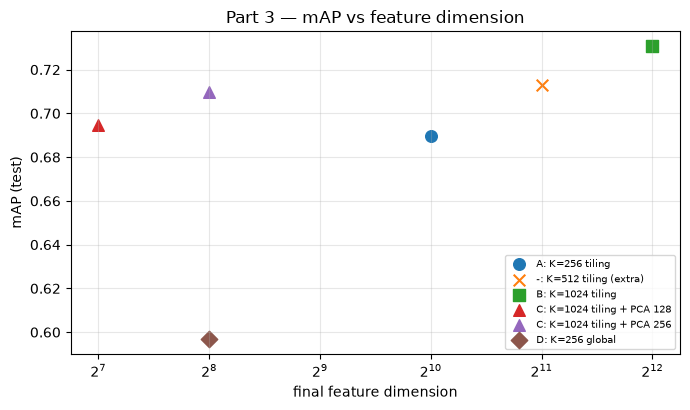

Reference (Part 2): VLAD mAP = 0.7270 (dim 10240),  FV mAP = 0.7191 (dim 20608)


In [24]:
# ── Part 3 — mAP vs dimension ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4.2))
mk = {'A': 'o', 'B': 's', 'C': '^', 'D': 'D', '-': 'x'}
for r in part3:
    ax.scatter(r['Final dim'], r['mAP'], marker=mk[r['Condition']], s=70, label=f'{r["Condition"]}: {r["Method"]}')
ax.set_xscale('log', base=2); ax.set_xlabel('final feature dimension'); ax.set_ylabel('mAP (test)')
ax.set_title('Part 3 — mAP vs feature dimension'); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

# Reference: Part 2 encoders (nominal dimension is not comparable to BoVW, see Discussion)
print(f'Reference (Part 2): VLAD mAP = {ap_vlad["mAP"]:.4f} (dim {dim_vlad}),  FV mAP = {ap_fv["mAP"]:.4f} (dim {dim_fv})')

---
# Discussion — answers to the handout questions

All hard-coded numbers below are *deterministic* quantities (AP/mAP, P@K, dimensions, storage) from the run of this notebook (seed 42, one fixed vocabulary per K).
Wall-clock timings change from run to run, so they are **not** quoted here: read them from the tables above. Validation has only 24 motorbike positives, so
validation differences of a few points are noisy; differences of ≲ 2 p.p. in test mAP should not be read as a ranking.

## Part 1

**Stage A — K and tiling.** The global histogram has $K$ dimensions, the 2×2 tiling $4K$ (one histogram per tile, concatenated). Validation AP (motorbike, L2) for K = 256 / 512 / 1024: 0.590 / 0.555 / 0.510 with tiling and 0.394 / 0.455 / 0.491 global.
K was chosen on validation (K = 256, 1024-d). Tiling helps at every K but the gain shrinks as K grows (+19.6, +10.0, +1.9 p.p.): at large K the tiled histogram is 4096-d, sparse, with only 96 positive training images.
The validation ordering of K is *not* what Part 3 finds on test (with Hellinger, test mAP rises with K: 0.690 → 0.713 → 0.731), so the 24-positive validation set is a weak basis for choosing K.
Tiling encodes *where* words occur, useful for objects with a consistent layout; the cost is a 4× larger, sparser representation for the same amount of data, which can hurt generalization when the layout varies.
Larger K = finer quantization (lower quantization error, more specific words), more capacity, but sparser histograms, dimension/storage that grow linearly with K, and a k-means assignment cost that grows with K.
The inspected images (scale from tiny to frame-filling, viewpoint, lighting and clutter changes, overlapping classes, vehicles and animals in the background) are described in the observations after the image grids.

**Stage B — what we observed (K = 256, L2, C = 1, training set; rerun if the configuration changes).** Best C = 1 (tiny C underfits: AP val 0.18). Training AP is 0.870 vs validation AP 0.590, i.e. much better on seen images than on new ones (≈ 96 positives in 1024 dimensions).
The 24 top-ranked training images are all motorbikes, mostly large side-on bikes with riders on tracks and roads; a few are small/distant bikes (e.g. next to a cow), which already suggests that context contributes.
The highest-ranked *negatives* are other vehicles and mechanical/cluttered scenes: a double-decker bus, a yellow bus, steam locomotives, a bicycle, computer desks — plus dogs and a duck on beach/grass — i.e. wheel/metal/dark-clutter patterns rather than "motorbike" specifically.
The lowest-ranked positives are scale/viewpoint outliers: tiny or distant bikes, a bike beside a cactus, a fish-eye photo, airborne stunt bikes.
Relevant visual words: for the two top-ranked images the word with the largest weight × count (word 139 of 256) collects patches that mix rider gear (helmets, coloured leathers) with straw/hay-bale and crowd textures; in the top image its keypoints lie on the bikes and riders *and* along the hay-bale wall behind them.
So the evidence is mixed: object-related patches (riders, wheels) and track context (hay bales, crowds, asphalt) that co-occurs with motorbikes in this dataset. We inspected two images and a few words, so this is a qualitative observation, not a quantified result.
The positive score of the top training image is negative (−0.08): with 10 % positives and an L2-normalized linear SVM, threshold 0 is too conservative, but the ranking, which AP measures, is unaffected.

**Stage C.** Motorbike test AP with the L2 baseline is 0.476 (P@5 = 0.80, P@20 = 0.65; 25 of the top 36 are motorbikes). The bias $b$ adds the same constant to every score of one fixed classifier, so it cannot change the order of the images (hence not the PR curve or AP); it only moves the operating threshold.
At threshold 0 this classifier returns no motorbike (TP = 0, FN = 125). That does **not** mean it cannot retrieve motorbikes — the ranking is clearly informative (AP 0.476 vs a chance level of ≈ 0.10) — only that threshold 0 is not an adequate operating point for this 10 %-positive problem; this is why AP/PR are the main metrics.
AP is high when positives are concentrated at the top: a negative ranked early costs precision that later positives have to recover, negatives ranked below all positives cost nothing.

**Stage D.** L2 baseline test AP: aeroplane 0.559, car 0.688, horse 0.598, motorbike 0.476, person 0.717 (mAP 0.607). The classes with the most training positives (person 820, car 301) have the highest AP and motorbike (96) the lowest, which is *compatible with* sample count mattering, but this does not show causality:
scale, intra-class variation, visual diversity, overlapping classes (person images that also contain horses) and the diversity of backgrounds can all contribute and were not isolated.
For the **final** configuration (Hellinger, tiling) the threshold-0 results on test are: aeroplane P 0.91 / R 0.25, car 0.69 / 0.67, person 0.71 / 0.68, and **no positive prediction at all for horse and motorbike** (TP = 0) despite mAP 0.69. The notebook also reports a threshold chosen on validation (max F1) for comparison.

**Stage E.** For L2-normalized $\mathbf h$, $K(\mathbf h,\mathbf h)=\lVert\mathbf h\rVert^2=1$ exactly, and by Cauchy–Schwarz $K(\mathbf h,\mathbf h')\le1$ with equality only for identical directions: the self-similarity is the maximum and the similarity between different images is the cosine of their angle (mean 0.36 on the validation images).
Self-similarity carries no information about the content (it is 1 for every image); normalization removes the *amount* of descriptors (image size/number of keypoints) and keeps the *distribution*. Unnormalized $K(\mathbf h,\mathbf h)\sim10^{7}$ varies enormously between images, so large/textured images dominate; for L1 it equals $\sum h_i^2$, a small image-dependent number (≈ 0.017).
*Is normalization related to performance?* For the **ranking**, yes: validation AP (tiling) none 0.417 < L1 0.471 < L2 0.590 (global 0.274 < 0.372 < 0.394). For **classification at the fixed threshold 0** the relation is not monotone: on the same validation set the unnormalized classifier has precision 0.48 / recall 0.50 (F1 0.49), whereas L1, L2 and Hellinger — which have much higher AP — predict no positive at all at threshold 0. AP and threshold-dependent metrics measure different things, especially with imbalanced classes.
*Spatial information, per category (validation, K = 256):* tiling is better than the global histogram for **all five** categories with L2 (aeroplane 0.607 vs 0.531, car 0.662 vs 0.599, horse 0.626 vs 0.568, motorbike 0.590 vs 0.394, person 0.691 vs 0.656) and for four of five with Hellinger (aeroplane is a tie: 0.883 vs 0.879).
So in *our* data removing spatial information did not help any class; the textbook argument — it can help classes whose appearance does not depend on position (less sparse, shift-invariant histogram) and hurt classes with a typical layout — is therefore a possible explanation of when it could happen, not something this experiment shows. Only a single K and the validation split were used.

**Stage F.** *Order of operations* (validation, motorbike, tiling): L1→sqrt, L1→sqrt→L2, sqrt→L2 and L2→sqrt→L2 give **identical** AP (0.7831). This is expected: for L1-normalized $\mathbf h$, $\lVert\sqrt{\mathbf h}\rVert_2^2=\sum_i h_i=1$, so the L2 step after the root is redundant, and $\sqrt{\mathbf h/a}/\lVert\sqrt{\mathbf h/a}\rVert_2$ does not depend on the scale $a$, so sqrt→L2 equals L1→sqrt.
The square root *alone* on raw counts (0.600) is much worse than the root of a normalized histogram (0.783). This comparison does **not** isolate an L2 step after the root; it shows that the per-image scale normalization (L1 or L2 *before* the root, which removes the dependence on the number of descriptors) is what has to accompany the root. Both ingredients help (normalization alone: L2 0.590; root alone: 0.600; together: 0.783).
Answer to the handout: normalize **before** the square root (L1, so that the map is exactly the Hellinger/Bhattacharyya feature map); the unit L2 norm after the root then comes for free, which is consistent with the rule of thumb for linear SVMs. L2→sqrt without a final L2 (feature norm ≈ 3.2) gives 0.791, within noise of 0.783.
Why the root matters: $\mathrm{d}\sqrt h/\mathrm{d}h = 1/(2\sqrt h)$ compresses large counts and amplifies small ones, so frequent (bursty) words dominate less and rare words contribute relatively more. Selected on validation: Hellinger, K = 256, tiling (val AP 0.783); on test it raises mAP from 0.607 (L2) to 0.690 and motorbike AP from 0.476 to 0.608.

**Stage G.** Validation AP vs training-set size (mean ± std over 3 subsampling seeds): L2 0.300 / 0.358 / 0.437 / 0.590 and Hellinger 0.268 / 0.445 / 0.565 / 0.784 for 10 / 25 / 50 / 100 % (n = 90 / 227 / 455 / 911). C is the value selected with the full training set and kept fixed (see Stage G).
Neither curve saturates: both are still rising between 50 % and 100 % (+15 and +22 p.p.). The Hellinger kernel is better from 25 % on; at 10 % (≈ 9 positives) the difference is within the seed spread. More examples would very likely help. Whether *more diverse* examples would help more than *more of the same* cannot be told from this curve; the std at 100 % is only the SVM shuffling seed.

## Part 2

**Dimensions (Stage H).** BoVW stores one count per word: $K$ values per tile (1024 for K = 256 with tiling). VLAD stores a $D$-dimensional residual per word: $K\times D$ per tile, 4 × 32 × 80 = 10 240 (10× the BoVW vector, 40 KB/image as float32). The FV has 20 608 dimensions (see Stage I for why it is not 20 480).
With only K = 32 centres VLAD carries much more information per word (the direction of the descriptors in each cell, not just how many) at a larger storage and SVM cost. Nominal dimensions are not interchangeable: BoVW's is the number of words, VLAD's/FV's is dominated by $D$. Storage figures are estimates (dimension × 4 bytes).

**Results (test).** mAP: BoVW K=256 L2 **0.607** → BoVW + Hellinger 0.690 → VLAD **0.727** → FV **0.719**. Changing only the encoding (same L2 + linear SVM) gives +12 p.p. mAP (BoVW → VLAD), largest for motorbike (0.476 → 0.690) and aeroplane (0.559 → 0.748).
Against the *tuned* BoVW (Hellinger) the VLAD gain is +3.7 p.p. at 10× the dimension and storage and a clearly longer SVM training time (see the timing table). VLAD/FV use only L2 here (power/intra normalization, optional in the handout, was not tried), so they may be under-tuned relative to the Hellinger BoVW; the comparison is therefore not "VLAD >> BoVW" but "VLAD ≳ tuned BoVW at a much higher cost".
*Retrieval quality for motorbike (test):* P@5 = P@10 = 1.0 for Hellinger-BoVW, VLAD and FV (L2 BoVW: 0.8 / 0.7); P@20: 0.65 (L2 BoVW), 0.90 (BoVW-H), 0.90 (VLAD), 0.95 (FV); P@50: 0.68 / 0.78 / 0.88 / 0.88; P@100: 0.49 / 0.62 / 0.71 / 0.66. VLAD and FV keep their precision deeper into the ranking than the tuned BoVW, which is where the extra dimensions pay off.

**FV vs VLAD (Stage I).** The FV adds second-order statistics (per-dimension variance gradients), soft GMM assignments and the mixture-weight gradient. It costs twice the dimension (80 KB/image), a GMM (EM) instead of k-means when building the encoder, a slower encoder and a longer SVM training (see the timing table). On this split FV is *not* better than VLAD in mAP (0.719 vs 0.727; better on horse and person, worse on aeroplane), a difference well inside what one split / one seed can resolve.
*Timing caveat:* encoding time = dense SIFT + descriptor PCA + encoding per image with the encoder preloaded, averaged over 50 test images; SIFT dominates, so the encoders differ little. Codebook/GMM fitting times were not re-measured.

## Part 3 — large vocabulary + PCA vs smaller vocabulary (test, Hellinger normalization, tiling)

| Condition | Dim | mAP | Macro-F1 (thr 0) | Accuracy (thr 0) | KB/img |
|---|---|---|---|---|---|
| A: K=256 | 1024 | 0.690 | 0.351 | 0.851 | 4.0 |
| extra: K=512 | 2048 | 0.713 | 0.360 | 0.852 | 8.0 |
| B: K=1024 | 4096 | 0.731 | 0.379 | 0.856 | 16.0 |
| C: K=1024 + PCA 128 | 128 (−96.9 %) | 0.695 | 0.406 | 0.860 | 0.5 |
| C: K=1024 + PCA 256 | 256 (−93.8 %) | 0.710 | 0.336 | 0.852 | 1.0 |
| D: K=256 global | 256 | 0.597 | 0.281 | 0.834 | 1.0 |

(PCA fitting, SVM training and inference times are in the output table of the Part 3 cell; they vary between runs and are not repeated here.)

**Does a larger codebook help before PCA?** Yes: mAP 0.690 → 0.713 → 0.731 for K = 256 → 512 → 1024. The largest per-class gains are horse (0.643 → 0.705) and motorbike (0.608 → 0.670); person +3.7, aeroplane +2.4, car +2.0 p.p. This is the opposite of the validation ranking in Part 1.

**Does PCA keep the gain, and how far can the dimension go down?** Partly. PCA → 256 (94 % of dimensions removed) keeps about half of the gain of K = 1024 over K = 256 (0.710 vs 0.731 / 0.690) and PCA → 128 about 12 % (0.695): a 16× (32×) smaller vector loses 2.1 (3.6) p.p. mAP with respect to B, but is not worse than condition A, which is 4× (8×) larger. PCA → 128 loses most on aeroplane and horse; person is almost unaffected.

**At a similar final dimension, is large + PCA better than a small codebook?** At 256 dimensions PCA-256 of K = 1024 (0.710) beats the K = 256 *global* histogram (0.597) by 11 p.p., **but this comparison is confounded**: condition D has no spatial information, while the PCA variant keeps the 2×2 tiling it was built from (worth +10–20 p.p. on validation in Part 1).
The fair comparison would be a small *tiled* vocabulary with the same dimension (e.g. K = 64 × 4 tiles = 256), which would require building new encodings that are not available here (no precomputed K = 64/128 encodings; extracting them from scratch is expensive). So we **cannot conclude** that "large vocabulary + PCA outperforms a small vocabulary"; we can only say it outperforms the 256-d global histogram, and that the difference cannot be attributed to the vocabulary size alone.

**Trade-offs.** PCA cuts storage (16 KB → 0.5–1 KB per image) and the SVM training time, but adds a one-off PCA fit and, in our numpy implementation, does *not* make inference cheaper (the projection has a cost; check the table). The cost of building the large representation (training and assigning 1024 words per descriptor) is paid anyway; PCA only lowers the cost of *storing and classifying* it.
*Metrics:* mAP measures the quality of the **ranking**; accuracy and macro-F1 here are one-vs-rest at the fixed threshold 0 and measure a single operating point. Accuracy ≈ 0.85 is dominated by the ~90 % negatives and does **not** mean that every category is recognized well: macro-F1 is much lower (0.28–0.41) and several categories have very low recall at threshold 0 (see Stages D/F). The two are not equivalent and need not move together.

**BoVW vs VLAD/FV.** A BoVW histogram has exactly K (per tile) dimensions that are highly redundant (counts of similar words), so compressing 4096 → 256 loses little; VLAD/FV dimensions grow with $K\times D$ (10 240 / 20 608 even at K = 32), so PCA (or smaller D/K) has a much larger practical effect on their storage and classifier cost. PCA on VLAD/FV was not run, so this is expected behaviour, not a measured result.

**Limitations.** One vocabulary per K (no re-fitting of k-means with other seeds), SVM/PCA seed 42, a single split, codebook-fitting and encoding times of the encoders not re-measured (they were built offline and were not recorded), VLAD/FV without power/intra normalization, no K = 64/128 tiled baseline.